# Neural population analysis — Hakim BMI packets

First-pass **neural** analyses prototyping the population-dynamics measures in the proposal on the real
BMI dataset. Companion to `first_pass_analysis.ipynb` (behavior; untouched). Reusable tools live in
`utilities/neural_analysis_utils.py` (imported as `na`); the analysis flow and all plotting are open
in this notebook. Per-day metrics are computed **once per mouse** into cached tidy tables.

**Preprocessing — binning, not smoothing.** Neural data are `(neurons, time)`, 30 Hz, non-negative
rates. We **bin** into non-overlapping ~166 ms windows (5 frames → 6 Hz) then z-score. Gaussian
smoothing injects autocorrelation between neighbouring frames, so a randomly subsampled PCA/FA design
matrix has non-independent samples and dimensionality is biased downward; binning gives genuinely
down-sampled, near-independent samples. (Empirically, same stable day, correct trials: smoothing→PR≈26,
binning→PR≈35.)

**Conditions:** correct = `[trialStart, trialEnd]` (variable length; reward lands ~0.4 s after
trialEnd → no consumption); incorrect = `[start, +20 s]`; baseline = no trial start within ±10 s;
reward-consumption = `[reward, +7 s]`. Dimensionality is sample-size dependent → matched sample counts.
Decoder/factor **weights ignored**; `factor_to_use` is only an axis label (2 = intuitive, 3 = new).

**Sections:** (2) per-day effective dim (matched PR, 4 conditions) · (3) scree / explained variance ·
(4) baseline dim vs mouse-weight % · (5) trajectory length & variability · (6) sliding windows +
reward-rate correlation · (7) manifold alignment across days · (8) FA-CV (optional) · (9) remapping
intuitive vs new axis · (10) one-vs-two trajectories · (11) **exploration trajectories** in PC pairs
(how the animal searches for the new axis) · (12) max cursor on incorrect trials vs neural metrics.

In [1]:
%matplotlib inline
import sys, os, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import seaborn as sns
from scipy.stats import pearsonr, spearmanr, mannwhitneyu, ttest_1samp
from sklearn.mixture import GaussianMixture

REPO = Path.cwd()
sys.path.insert(0, str(REPO / "utilities"))
import importlib, neural_analysis_utils as na
importlib.reload(na)
import richfile as rfs
na.register_richfile_types(rfs)

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

# ============================ CONFIG ============================
SR = 30                              # Hz (raw)
DATA_ROOT = Path(r"C:\Data\datasets\bmi_packets\bmi_packets")
EXP_LOG = DATA_ROOT / "RH + GH experiment log.xlsx"
OUTPUT_ROOT = REPO / "output"
MICE = ["mouse_0403L", "mouse_0322R", "mouse_0403R", "mouse_0916N"]
MAX_DAYS_PER_PHASE = None            # cap days per phase for a quick test; None = all

# preprocessing: BIN (non-overlapping mean) then z-score
BIN_SIZE_FRAMES = 5                  # ~166 ms; effective rate SR/BIN
SR_BINNED = SR / BIN_SIZE_FRAMES     # 6 Hz
K_PC = 10                            # fixed subspace for trajectory length / alignment

# conditions
INCORRECT_WINDOW_SEC = 20.0
BASELINE_EXCLUDE_SEC = 10.0
BASELINE_MIN_LEN_SEC = 2.0
REWARD_CONSUME_SEC = 7.0
CONDITIONS = ["correct", "incorrect", "baseline", "reward_consume"]

# dimensionality (matched participation ratio); counts are in BINNED samples
MATCHED_N_SAMPLES_DAY = 2000
MATCHED_N_SAMPLES_AXIS = 1200        # per-axis (remap) — fewer trials
MATCHED_N_SAMPLES_WIN = 300
MATCHED_N_BOOT = 8
MIN_TRIALS = 5
N_SCREE = 30                         # PCs to keep for scree plots

# trajectory / windows
N_RESAMPLE = 50
WIN_SEC = 150.0
STEP_SEC = 60.0
REWARD_SMOOTH_WIN = 5

# FA-CV (proposal's method) — slow diagnostic, off by default
RUN_FA_CV = False
FA_CONDITIONS = ["correct"]
FA_DIMS = [2, 3, 5, 8, 12, 20, 35, 50]
FA_SAMPLE_CAP = 5000
FA_FOLDS = 4
FA_N_JOBS = -1

USE_CACHE = True
PARAM_TAG = f"b{BIN_SIZE_FRAMES}_k{K_PC}_m{MATCHED_N_SAMPLES_DAY}w{MATCHED_N_SAMPLES_WIN}_rc{int(REWARD_CONSUME_SEC)}_win{int(WIN_SEC)}-{int(STEP_SEC)}"
sns.set_context("notebook")
print("config loaded; mice:", MICE, "| bin:", BIN_SIZE_FRAMES, "frames ->", SR_BINNED, "Hz | tag:", PARAM_TAG)

config loaded; mice: ['mouse_0403L', 'mouse_0322R', 'mouse_0403R', 'mouse_0916N'] | bin: 5 frames -> 6.0 Hz | tag: b5_k10_m2000w300_rc7_win150-60


## 1 · Data access, phases & preprocessing

`preprocess_day` loads a day, **bins** it (non-overlapping mean) and z-scores, and returns the binned
session plus trials/reward frames rescaled to bin units (and the raw-frame trials, kept for the cursor
analysis in Section 12). All condition/window helpers are given `SR_BINNED`, so everything downstream
is consistent in bin units.

In [2]:
from dataclasses import dataclass

@dataclass
class Mouse:
    name: str; r: object; days: list; day0: str; day0_idx: int
    stable_days: list; remap_days: list; factors_per_day: dict; out: Path; weight: dict

def load_mouse(name):
    r = na.open_mouse(rfs, DATA_ROOT, name)
    days = na.get_day_list(r)
    day0 = r["date_day0"].load()
    day0 = str(np.asarray(day0).ravel()[0]) if not isinstance(day0, str) else day0
    day0_idx = days.index(day0) if day0 in days else 0
    fpd = {}
    for d in days:
        tr = na.get_true_bmi_trials(na.get_trials_df(r, d))
        fpd[d] = np.unique(tr.factor[np.isfinite(tr.factor)])
    usable = [d for d in days[day0_idx:] if fpd[d].size >= 1]
    stable = [d for d in usable if fpd[d].size == 1]
    remap  = [d for d in usable if fpd[d].size > 1]
    if MAX_DAYS_PER_PHASE:
        stable, remap = stable[:MAX_DAYS_PER_PHASE], remap[:MAX_DAYS_PER_PHASE]
    weight = na.load_weight_percentage(EXP_LOG, name, days)
    out = OUTPUT_ROOT / name / "neural_analysis"; out.mkdir(parents=True, exist_ok=True)
    return Mouse(name, r, days, day0, day0_idx, stable, remap, fpd, out, weight)

def preprocess_day(mo, day):
    neural = na.load_neural(mo.r, day)
    X = na.bin_and_zscore(neural, BIN_SIZE_FRAMES, zscore=True)
    trials_raw = na.get_true_bmi_trials(na.get_trials_df(mo.r, day))   # 30 Hz frames
    trials = na.bin_trials(trials_raw, BIN_SIZE_FRAMES)                # bin units
    rew = na.bin_frames(na.get_active_reward_frames(mo.r, day), BIN_SIZE_FRAMES)
    return X, trials, rew, X.shape[1], trials_raw

def build_conditions(X, trials, reward_frames, T, *, factor=None):
    return {
        "correct":        na.correct_trial_intervals(trials, T, factor=factor),
        "incorrect":      na.incorrect_trial_intervals(trials, T, window_sec=INCORRECT_WINDOW_SEC, sr=SR_BINNED, factor=factor),
        "baseline":       na.baseline_intervals(trials, T, exclude_sec=BASELINE_EXCLUDE_SEC, sr=SR_BINNED, min_len_sec=BASELINE_MIN_LEN_SEC),
        "reward_consume": na.reward_consumption_intervals(reward_frames, T, dur_sec=REWARD_CONSUME_SEC, sr=SR_BINNED),
    }

def n_trials_of(name, trials, factor=None):
    if name == "correct":   return int(trials.mask(success=1, factor=factor).sum())
    if name == "incorrect": return int(trials.mask(success=0, factor=factor).sum())
    return None

mice = {m: load_mouse(m) for m in MICE}
for m, mo in mice.items():
    wv = np.array([mo.weight[d] for d in mo.days], float)
    print(f"{m:14s} days={len(mo.days):2d} day0={mo.day0} stable={len(mo.stable_days):2d} "
          f"remap={len(mo.remap_days):2d} weight%range={np.nanmin(wv):.2f}-{np.nanmax(wv):.2f}")

mouse_0403L    days=36 day0=20230703 stable=20 remap=15 weight%range=0.82-0.86
mouse_0322R    days=35 day0=20230425 stable=30 remap= 0 weight%range=0.77-0.80
mouse_0403R    days= 6 day0=20230703 stable= 4 remap= 0 weight%range=0.78-0.82
mouse_0916N    days= 4 day0=20231023 stable= 2 remap= 0 weight%range=0.76-0.77


## 2 · Single-pass per-day computation

Each day is loaded/binned **once**; then dimensionality (4 conditions, matched PR), trajectory
length/variability, sliding-window metrics, scree spectra, and (optionally) FA-CV are computed from
it. `compute_mouse` caches tidy tables to `output/<mouse>/neural_analysis/` (filenames embed the
parameters, so changing a parameter recomputes).

In [3]:
def day_dim_rows(mo, day, phase, X, trials, rew, T):
    conds = build_conditions(X, trials, rew, T)
    rows = []
    for cname in CONDITIONS:
        ivs = conds[cname]; ns = na.n_samples(ivs)
        if ns < MATCHED_N_SAMPLES_DAY // 3:
            continue
        Xc = na.intervals_to_matrix(X, ivs)
        spec = na.pca_spectrum(Xc)
        pr_m, pr_sd = na.participation_ratio_matched(Xc, MATCHED_N_SAMPLES_DAY, n_boot=MATCHED_N_BOOT)
        rows.append(dict(mouse=mo.name, day=day, day_from0=mo.days.index(day)-mo.day0_idx, phase=phase,
                         condition=cname, n_trials=n_trials_of(cname, trials), n_samples=ns,
                         pr_matched=pr_m, pr_matched_sd=pr_sd, pr_raw=spec.participation_ratio,
                         d80=na.dim_at_variance(spec, 0.8), d90=na.dim_at_variance(spec, 0.9)))
    return rows

def day_scree_row(mo, day, phase, X, trials, T):
    ivs = na.correct_trial_intervals(trials, T)
    if na.n_samples(ivs) < N_SCREE + 5:
        return None
    ratio = na.pca_spectrum(na.intervals_to_matrix(X, ivs)).ratio[:N_SCREE]
    row = dict(mouse=mo.name, day=day, day_from0=mo.days.index(day)-mo.day0_idx, phase=phase)
    row.update({f"pc{i+1}": (ratio[i] if i < len(ratio) else np.nan) for i in range(N_SCREE)})
    return row

def day_trajectory(mo, day, phase, X, trials, T, ref_sub):
    ivs = na.correct_trial_intervals(trials, T)
    if len(ivs) < 2:
        return None, None
    Xc = na.intervals_to_matrix(X, ivs)
    sub = na.fit_subspace(Xc, K_PC)
    trajs = [sub.project(t) for t in na.intervals_to_trajectories(X, ivs)]
    ts = na.trajectory_stats(trajs, n_resample=N_RESAMPLE)
    row = dict(mouse=mo.name, day=day, day_from0=mo.days.index(day)-mo.day0_idx, phase=phase,
               n_trials=ts.n_trials, mean_length=ts.mean_length, length_sd=ts.length_sd,
               var_raw=ts.var_raw, var_per_length=ts.var_per_length, var_per_meanpath=ts.var_per_meanpath,
               subspace_var=float(sub.explained_ratio.sum()),
               alignment_to_ref=(na.alignment_index(ref_sub, sub) if ref_sub is not None else 1.0))
    return row, sub

def day_window_rows(mo, day, phase, X, trials, rew, T, sub):
    ivs = na.correct_trial_intervals(trials, T)
    trajs = [sub.project(t) for t in na.intervals_to_trajectories(X, ivs)] if (sub is not None and ivs) else []
    starts = np.array([s for s, e in ivs]) if ivs else np.array([])
    wins = na.sliding_windows(T, win_sec=WIN_SEC, step_sec=STEP_SEC, sr=SR_BINNED)
    rr = na.reward_rate_in_windows(rew, wins, sr=SR_BINNED)
    rr_sm = na.smooth_series(rr, REWARD_SMOOTH_WIN)
    remap_frame = na.remapping_start_frame(trials) if phase == "remap" else None
    min_len = int(round(SR_BINNED))
    rows = []
    for i, w in enumerate(wins):
        ivw = na.intervals_within(ivs, w.start, w.end, min_len=min_len) if ivs else []
        pr_m = np.nan
        if na.n_samples(ivw) >= MATCHED_N_SAMPLES_WIN:
            pr_m, _ = na.participation_ratio_matched(na.intervals_to_matrix(X, ivw), MATCHED_N_SAMPLES_WIN, n_boot=1)
        tlen, tvar = np.nan, np.nan
        if trajs and starts.size:
            in_w = np.where((starts >= w.start) & (starts < w.end))[0]
            if in_w.size >= MIN_TRIALS:
                tt = na.trajectory_stats([trajs[j] for j in in_w], n_resample=N_RESAMPLE)
                tlen, tvar = tt.mean_length, tt.var_per_length
        center = w.center_sec / 60.0
        rows.append(dict(mouse=mo.name, day=day, day_from0=mo.days.index(day)-mo.day0_idx, phase=phase,
                         win_idx=i, center_min=center,
                         center_min_aligned=(center - remap_frame/SR_BINNED/60.0) if remap_frame is not None else np.nan,
                         pr_matched=pr_m, traj_length=tlen, traj_var=tvar,
                         reward_rate=rr[i], reward_rate_smooth=rr_sm[i]))
    return rows

def day_fa_rows(mo, day, phase, X, trials, rew, T):
    conds = build_conditions(X, trials, rew, T)
    rows = []
    for cname in FA_CONDITIONS:
        Xc = na.intervals_to_matrix(X, conds[cname])
        if Xc.shape[0] < FA_FOLDS * 5: continue
        fa = na.cv_fa_dimensionality(Xc, dims=FA_DIMS, n_folds=FA_FOLDS, sample_cap=FA_SAMPLE_CAP, n_jobs=FA_N_JOBS)
        for d, ll, se in zip(fa["dims"], fa["mean_ll"], fa["sem_ll"]):
            rows.append(dict(mouse=mo.name, day=day, day_from0=mo.days.index(day)-mo.day0_idx, phase=phase,
                             condition=cname, dim=int(d), mean_ll=ll, sem_ll=se,
                             best_dim=fa["best_dim"], best_is_edge=fa["best_is_edge"]))
    return rows

In [4]:
def compute_mouse(mo):
    dim_rows, traj_rows, win_rows, fa_rows, scree_rows = [], [], [], [], []
    ref_sub = None
    for day in tqdm(mo.stable_days + mo.remap_days, desc=mo.name):
        phase = "stable" if day in mo.stable_days else "remap"
        X, trials, rew, T, _ = preprocess_day(mo, day)
        dim_rows += day_dim_rows(mo, day, phase, X, trials, rew, T)
        sc = day_scree_row(mo, day, phase, X, trials, T)
        if sc: scree_rows.append(sc)
        trow, sub = day_trajectory(mo, day, phase, X, trials, T, ref_sub)
        if trow is not None:
            traj_rows.append(trow)
            if ref_sub is None: ref_sub = sub
        win_rows += day_window_rows(mo, day, phase, X, trials, rew, T, sub)
        if RUN_FA_CV: fa_rows += day_fa_rows(mo, day, phase, X, trials, rew, T)
    return (pd.DataFrame(dim_rows), pd.DataFrame(traj_rows), pd.DataFrame(win_rows),
            pd.DataFrame(fa_rows), pd.DataFrame(scree_rows))

def compute_or_load(mo):
    names = ["dim_table", "traj_table", "window_table", "fa_cv_table", "scree_table"]
    fps = [mo.out / f"{n}_{PARAM_TAG}.csv" for n in names]
    core = [0, 1, 2, 4]  # dim, traj, window, scree
    core_ok = USE_CACHE and all(fps[i].exists() and fps[i].stat().st_size > 0 for i in core)
    fa_ok = (not RUN_FA_CV) or (fps[3].exists() and fps[3].stat().st_size > 0)
    if core_ok and fa_ok:
        return tuple(pd.read_csv(fp) if (fp.exists() and fp.stat().st_size > 0) else pd.DataFrame() for fp in fps)
    dfs = compute_mouse(mo)
    for j, (df, fp) in enumerate(zip(dfs, fps)):
        if j == 3 and not RUN_FA_CV: continue
        df.to_csv(fp, index=False)
    return dfs

_t = {m: compute_or_load(mo) for m, mo in mice.items()}
dim_df   = pd.concat([t[0] for t in _t.values()], ignore_index=True)
traj_df  = pd.concat([t[1] for t in _t.values()], ignore_index=True)
win_df   = pd.concat([t[2] for t in _t.values()], ignore_index=True)
fa_df    = pd.concat([t[3] for t in _t.values()], ignore_index=True) if RUN_FA_CV else pd.DataFrame()
scree_df = pd.concat([t[4] for t in _t.values()], ignore_index=True)
print("dim", dim_df.shape, "| traj", traj_df.shape, "| win", win_df.shape,
      "| scree", scree_df.shape, "| fa", fa_df.shape)
dim_df.head()

dim (276, 12) | traj (71, 12) | win (4418, 12) | scree (71, 34) | fa (0, 0)


,mouse,day,day_from0,phase,condition,n_trials,n_samples,pr_matched,pr_matched_sd,pr_raw,d80,d90
0,mouse_0403L,20230705,1,stable,correct,223.0,5535,70.675042,1.971456,72.972678,224,309
1,mouse_0403L,20230705,1,stable,incorrect,24.0,2880,58.162735,1.052608,58.763153,177,263
2,mouse_0403L,20230705,1,stable,baseline,NaN,4693,93.567575,1.171188,96.933665,216,300
3,mouse_0403L,20230705,1,stable,reward_consume,NaN,9366,87.660123,1.452741,90.515654,233,319
4,mouse_0403L,20230706,2,stable,correct,218.0,6808,58.414217,1.579909,59.452069,235,319


## 2b · Effective dimensionality per day (matched participation ratio)

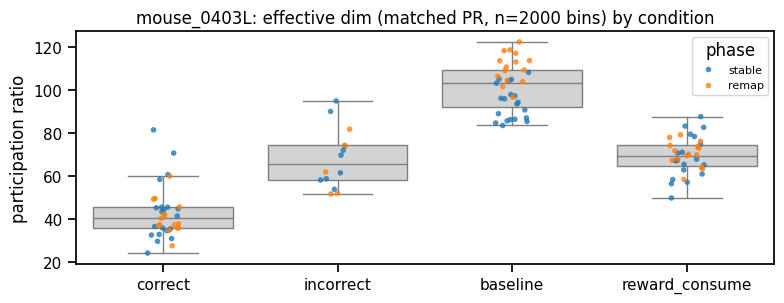

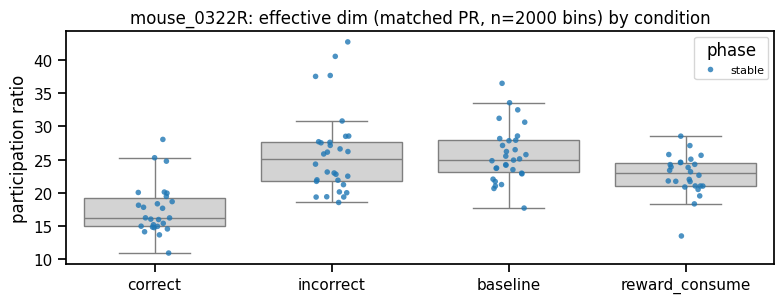

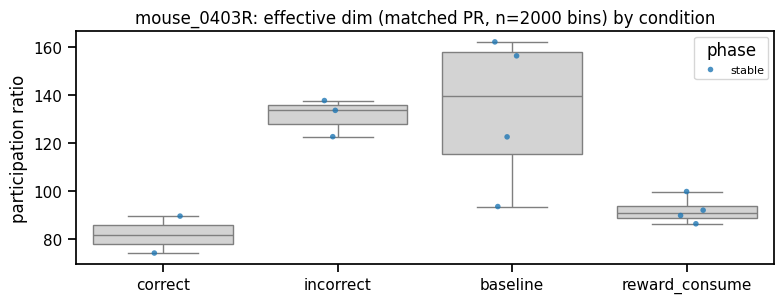

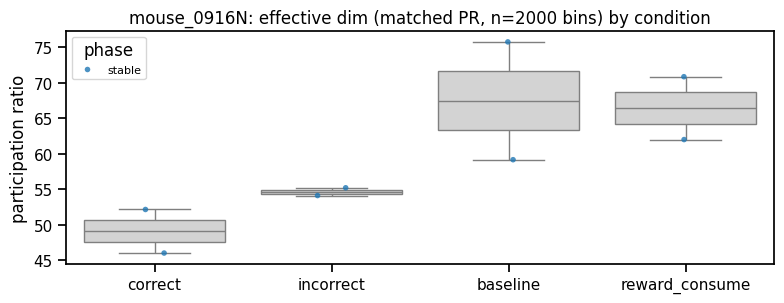

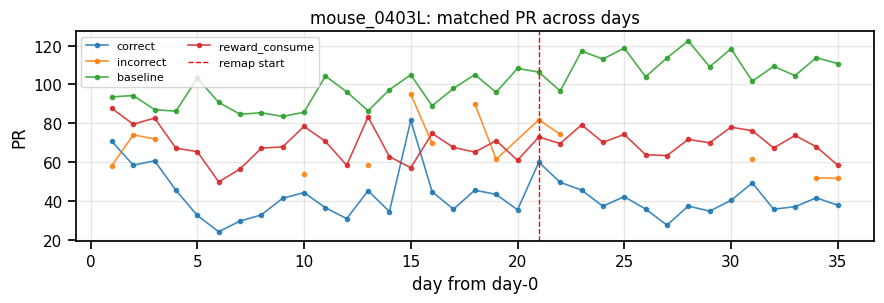

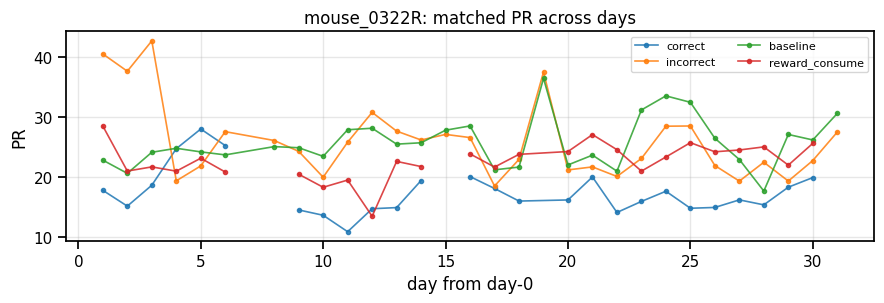

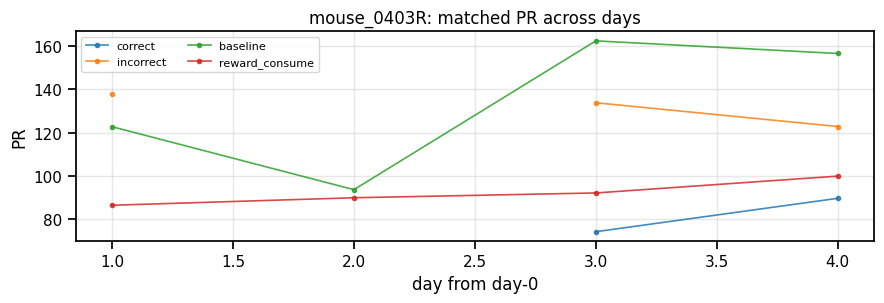

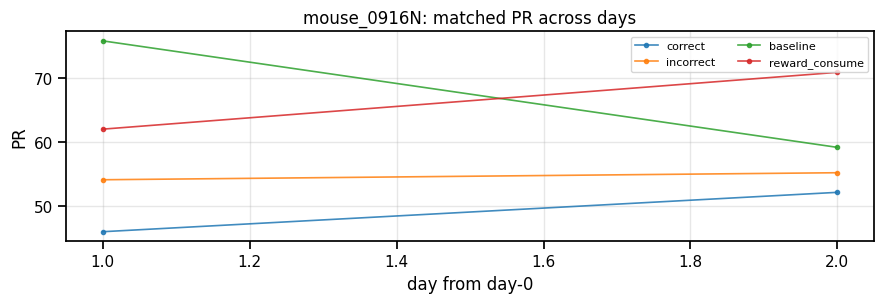

In [5]:
for m, mo in mice.items():
    sub = dim_df[dim_df.mouse == m]
    if sub.empty: continue
    fig, ax = plt.subplots(figsize=(8, 3.2))
    sns.boxplot(data=sub, x="condition", y="pr_matched", order=CONDITIONS, color="lightgray", fliersize=0, ax=ax)
    sns.stripplot(data=sub, x="condition", y="pr_matched", order=CONDITIONS, hue="phase", size=4, alpha=0.8, ax=ax)
    ax.set(title=f"{m}: effective dim (matched PR, n={MATCHED_N_SAMPLES_DAY} bins) by condition",
           ylabel="participation ratio", xlabel=""); ax.legend(title="phase", fontsize=8)
    fig.tight_layout(); fig.savefig(mo.out / f"{m}_dim_by_condition.png", dpi=150); plt.show()

for m, mo in mice.items():
    sub = dim_df[dim_df.mouse == m]
    if sub.empty: continue
    fig, ax = plt.subplots(figsize=(9, 3.2))
    for cname in CONDITIONS:
        s = sub[sub.condition == cname].sort_values("day_from0")
        if not s.empty: ax.plot(s.day_from0, s.pr_matched, "o-", ms=3, lw=1.2, label=cname, alpha=0.85)
    if mo.remap_days: ax.axvline(mo.days.index(mo.remap_days[0]) - mo.day0_idx, color="r", ls="--", lw=1, label="remap start")
    ax.set(title=f"{m}: matched PR across days", xlabel="day from day-0", ylabel="PR")
    ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(mo.out / f"{m}_dim_across_days.png", dpi=150); plt.show()

## 3 · Explained variance per PC (scree)

Per-PC explained-variance ratio of the **correct-trial** covariance, one line per day (colour = day)
plus the across-day mean, for each animal. The left panel is the individual spectrum (how fast
variance falls off); the right is cumulative. A slow fall-off / shallow cumulative curve is the
signature of the high effective dimensionality seen in Section 2.

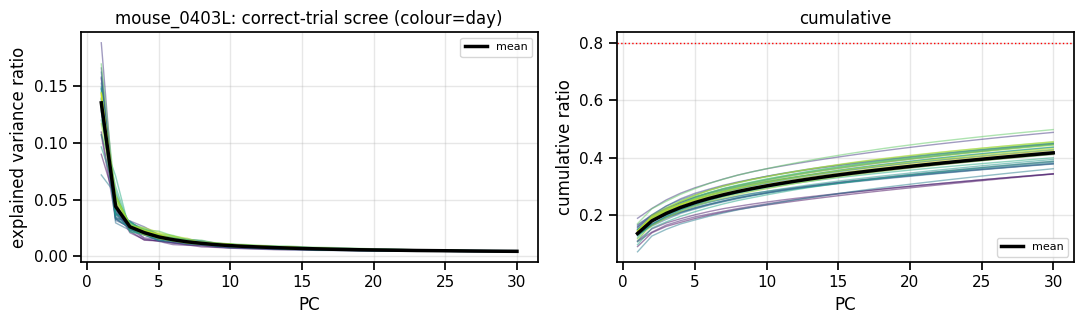

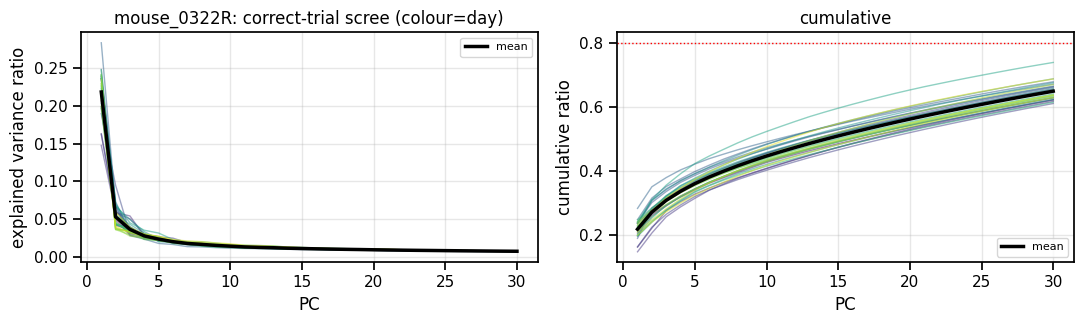

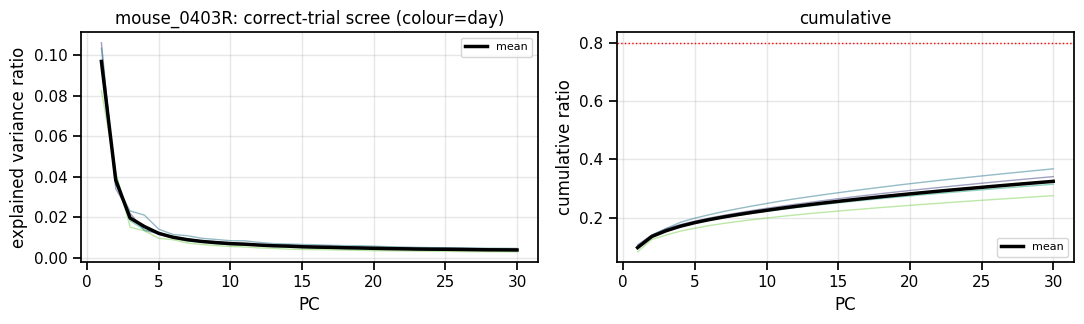

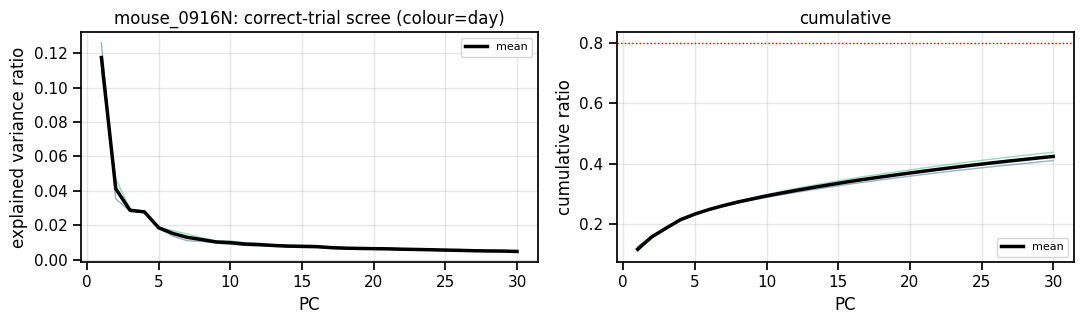

In [6]:
pc_cols = [f"pc{i+1}" for i in range(N_SCREE)]
for m, mo in mice.items():
    sub = scree_df[scree_df.mouse == m]
    if sub.empty: continue
    days = sorted(sub.day.unique()); pal = sns.color_palette("viridis", len(days))
    x = np.arange(1, N_SCREE + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    for c, day in zip(pal, days):
        r = sub[sub.day == day][pc_cols].to_numpy().ravel()
        axes[0].plot(x, r, color=c, alpha=0.5, lw=1)
        axes[1].plot(x, np.cumsum(r), color=c, alpha=0.5, lw=1)
    mean_r = sub[pc_cols].mean(axis=0).to_numpy()
    axes[0].plot(x, mean_r, "k-", lw=2.5, label="mean")
    axes[1].plot(x, np.cumsum(mean_r), "k-", lw=2.5, label="mean")
    axes[0].set(title=f"{m}: correct-trial scree (colour=day)", xlabel="PC", ylabel="explained variance ratio")
    axes[1].set(title="cumulative", xlabel="PC", ylabel="cumulative ratio"); axes[1].axhline(0.8, color="r", ls=":", lw=1)
    for a in axes: a.legend(fontsize=8); a.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(mo.out / f"{m}_scree.png", dpi=150); plt.show()

## 4 · Does baseline dimensionality track mouse weight %?

Question: does effective dimensionality of **baseline** (spontaneous, inter-trial) activity correlate
with the mouse's weight percentage (a proxy for restriction / motivational drive)? We join each day's
baseline matched-PR with that day's weight %. Only `mouse_0403L` has an appreciable weight range
(~0.82–0.86); the others are near-constant → uninformative.

**Important confound:** baseline PR and weight both drift *monotonically across training* (PR up,
weight down), so any raw PR–weight correlation is largely a training-day artefact. We therefore also
report the **partial correlation controlling for day** and split by phase — that is the honest test.

,mouse,condition,n,spearman_r,spearman_p,partial_r_day,partial_p_day,note
0,mouse_0403L,baseline,35,-0.642,0.000,-0.214,0.217,
1,mouse_0322R,baseline,30,0.043,0.823,0.062,0.746,
2,mouse_0403R,baseline,4,NaN,NaN,NaN,NaN,weight ~constant / too few
3,mouse_0916N,baseline,2,NaN,NaN,NaN,NaN,weight ~constant / too few
4,mouse_0403L,correct,35,0.246,0.155,0.306,0.074,
5,mouse_0322R,correct,26,0.474,0.015,0.595,0.001,
6,mouse_0403R,correct,2,NaN,NaN,NaN,NaN,weight ~constant / too few
7,mouse_0916N,correct,2,NaN,NaN,NaN,NaN,weight ~constant / too few


spearman_* = raw correlation; partial_r_day = controlling for training day. If the raw correlation vanishes after controlling for day, it was a day confound.


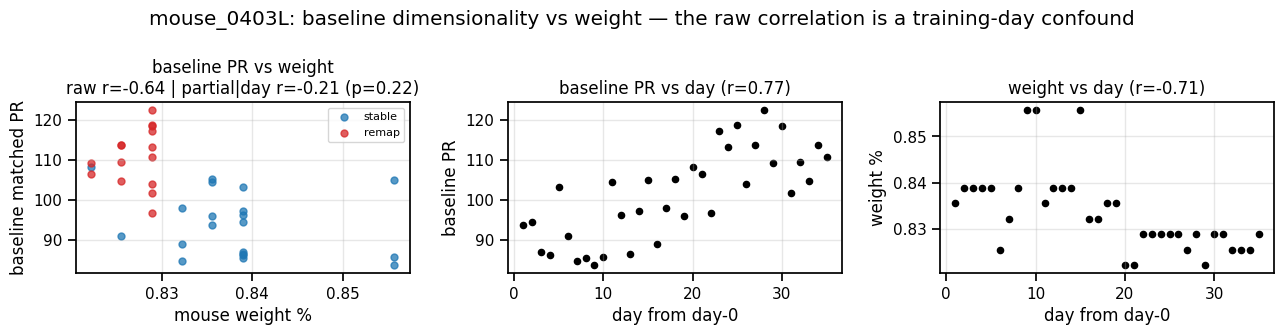

In [7]:
def partial_corr_control(y, x, z):
    # partial (linear) correlation of y and x controlling for z: Pearson of residuals
    def resid(v):
        A = np.vstack([z.astype(float), np.ones_like(z, dtype=float)]).T
        c, *_ = np.linalg.lstsq(A, v, rcond=None); return v - A @ c
    return pearsonr(resid(np.asarray(y, float)), resid(np.asarray(x, float)))

rows = []
for cond in ["baseline", "correct"]:
    for m, mo in mice.items():
        s = dim_df[(dim_df.mouse == m) & (dim_df.condition == cond)].copy()
        if s.empty: continue
        s["weight"] = [mo.weight.get(str(d), np.nan) for d in s.day]   # str(): day may be int from CSV
        d = s[["pr_matched", "weight", "day_from0"]].dropna()
        if d.weight.nunique() < 3 or len(d) < 5:
            rows.append(dict(mouse=m, condition=cond, n=len(d), spearman_r=np.nan, spearman_p=np.nan,
                             partial_r_day=np.nan, partial_p_day=np.nan, note="weight ~constant / too few")); continue
        sr, sp = spearmanr(d.pr_matched, d.weight)
        pr, pp = partial_corr_control(d.pr_matched.values, d.weight.values, d.day_from0.values)
        rows.append(dict(mouse=m, condition=cond, n=len(d), spearman_r=sr, spearman_p=sp,
                         partial_r_day=pr, partial_p_day=pp, note=""))
weight_corr = pd.DataFrame(rows)
display(weight_corr.round(3))
print("spearman_* = raw correlation; partial_r_day = controlling for training day. "
      "If the raw correlation vanishes after controlling for day, it was a day confound.")

# mouse_0403L baseline: scatter (by phase) + the two confounding day-trends
m = "mouse_0403L"; mo = mice[m]
s = dim_df[(dim_df.mouse == m) & (dim_df.condition == "baseline")].copy()
s["weight"] = [mo.weight.get(str(d), np.nan) for d in s.day]
dd = s[["pr_matched", "weight", "day_from0"]].dropna()
sr, _ = spearmanr(dd.pr_matched, dd.weight); pr, pp = partial_corr_control(dd.pr_matched.values, dd.weight.values, dd.day_from0.values)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
    ss = s[s.phase == ph]; axes[0].scatter(ss.weight, ss.pr_matched, s=25, alpha=0.75, color=cc, label=ph)
axes[0].set(title=f"baseline PR vs weight\nraw r={sr:.2f} | partial|day r={pr:.2f} (p={pp:.2f})",
            xlabel="mouse weight %", ylabel="baseline matched PR"); axes[0].legend(fontsize=8)
axes[1].scatter(s.day_from0, s.pr_matched, c="k", s=20)
axes[1].set(title=f"baseline PR vs day (r={spearmanr(dd.day_from0, dd.pr_matched)[0]:.2f})", xlabel="day from day-0", ylabel="baseline PR")
axes[2].scatter(s.day_from0, s.weight, c="k", s=20)
axes[2].set(title=f"weight vs day (r={spearmanr(dd.day_from0, dd.weight)[0]:.2f})", xlabel="day from day-0", ylabel="weight %")
for a in axes: a.grid(alpha=0.3)
fig.suptitle(f"{m}: baseline dimensionality vs weight — the raw correlation is a training-day confound")
fig.tight_layout(); fig.savefig(mo.out / f"{m}_dim_vs_weight.png", dpi=150); plt.show()

## 5 · Trajectory length & variability (correct trials)

Per correct trial in the day's fixed `K_PC` subspace we measure **trajectory length** (summed step
length start→reward) and **trial-to-trial variability**. Variability is computed at matched
*normalised* times: every trial is time-warped to `N_RESAMPLE` points, the cross-trial variance is
taken at each normalised time point (summed over the `K_PC` dimensions), then averaged over time. Call
that **`var_raw`** — the actual spatial scatter of trials about their mean path, in
(z-scored-activity)² units of the subspace.

### What the normalised versions mean — and why `var_raw` is the one to trust
* **`var_per_length` = `var_raw` / `mean_length`²** — meant to ask "is the scatter large *relative to how
  far the trajectory travels*?"
* **`var_per_meanpath` = `var_raw` / Var(mean trajectory)**. Here **Var(mean trajectory)** — the
  "mean-path variance" — is the variance *across time* of the **trial-averaged** trajectory, summed over
  dimensions: how much the average path itself sweeps through state space. So `var_per_meanpath` is a
  **noise-to-signal ratio** — cross-trial scatter divided by the spatial extent of the mean path. A
  value of 10 means single trials scatter ~10× more (in variance) than the averaged path travels.

**Both normalisations are dominated by their denominators here.** Across days `var_raw` barely moves
(CV ≈ 0.13) while `mean_length` varies ~4× (CV ≈ 0.34), so dividing by length² turns a ~1.3× effect into
a ~25× spread: `var_per_length` correlates with `mean_length` at **r ≈ −0.98** but with `var_raw` at only
r ≈ +0.47. The very small values you noticed (~0.005) are simply `var_raw`/`length²` with a large
length — not evidence of low variability. The next cell shows this explicitly.

### A less biased variability estimate
`var_raw` is not directly comparable across days either: it grows with the number of trials available
(r ≈ +0.71 with `n_trials`), since more trials sample the scatter more completely. We therefore also
compute **`var_matched`** — the same quantity with the trial count held **fixed** (`MATCH_N_TRIALS`,
bootstrapped). That is the version to compare across days and phases, with length reported
*separately* rather than divided out.

In [8]:
MATCH_N_TRIALS = 60          # fixed trial count for the unbiased variability estimate

def matched_variance_rows(mo):
    rows = []
    for day in tqdm(mo.stable_days + mo.remap_days, desc=f"var-matched {mo.name}"):
        X, trials, rew, T, _ = preprocess_day(mo, day)
        ivs = na.correct_trial_intervals(trials, T)
        if len(ivs) < 2: continue
        sub = na.fit_subspace(na.intervals_to_matrix(X, ivs), K_PC)
        trajs = [sub.project(t) for t in na.intervals_to_trajectories(X, ivs)]
        vm, vsd = na.trajectory_variance_matched(trajs, MATCH_N_TRIALS, n_resample=N_RESAMPLE, n_boot=10)
        rows.append(dict(mouse=mo.name, day=day, day_from0=mo.days.index(day) - mo.day0_idx,
                         phase="stable" if day in mo.stable_days else "remap",
                         var_matched=vm, var_matched_sd=vsd))
    return pd.DataFrame(rows)

vm_fp = OUTPUT_ROOT / f"var_matched_{PARAM_TAG}_n{MATCH_N_TRIALS}.csv"
if USE_CACHE and vm_fp.exists():
    var_m = pd.read_csv(vm_fp); var_m["day"] = var_m["day"].astype(str)
else:
    var_m = pd.concat([matched_variance_rows(mo) for mo in mice.values()], ignore_index=True)
    var_m.to_csv(vm_fp, index=False)
traj_df["day"] = traj_df["day"].astype(str)
traj2 = traj_df.merge(var_m[["mouse", "day", "var_matched", "var_matched_sd"]], on=["mouse", "day"], how="left")

# --- diagnostic: what actually drives var_per_length? ---
d0 = traj2[traj2.mouse == "mouse_0403L"]
print("mouse_0403L, across days:")
for a, b in [("var_per_length", "mean_length"), ("var_per_length", "var_raw"),
             ("var_raw", "n_trials"), ("var_matched", "n_trials"), ("var_matched", "mean_length")]:
    x = d0[[a, b]].dropna(); rho, pv = spearmanr(x[a], x[b])
    print(f"  {a:15s} vs {b:12s}: Spearman r={rho:+.3f} p={pv:.4f}")
print(f"  coefficient of variation: mean_length={d0.mean_length.std()/d0.mean_length.mean():.2f}  "
      f"var_raw={d0.var_raw.std()/d0.var_raw.mean():.2f}  "
      f"var_matched={d0.var_matched.std()/d0.var_matched.mean():.2f}  "
      f"var_per_length={d0.var_per_length.std()/d0.var_per_length.mean():.2f}")
print("  -> var_per_length is essentially a restatement of trajectory length; use var_matched instead.")

mouse_0403L, across days:
  var_per_length  vs mean_length : Spearman r=-0.979 p=0.0000
  var_per_length  vs var_raw     : Spearman r=+0.470 p=0.0044
  var_raw         vs n_trials    : Spearman r=+0.713 p=0.0000
  var_matched     vs n_trials    : Spearman r=+0.716 p=0.0000
  var_matched     vs mean_length : Spearman r=-0.298 p=0.0817
  coefficient of variation: mean_length=0.34  var_raw=0.13  var_matched=0.13  var_per_length=0.90
  -> var_per_length is essentially a restatement of trajectory length; use var_matched instead.


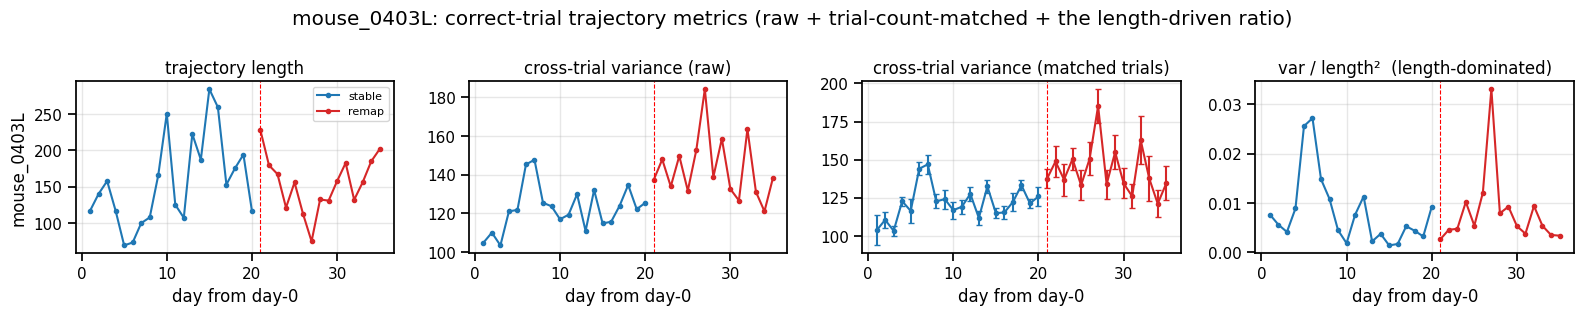

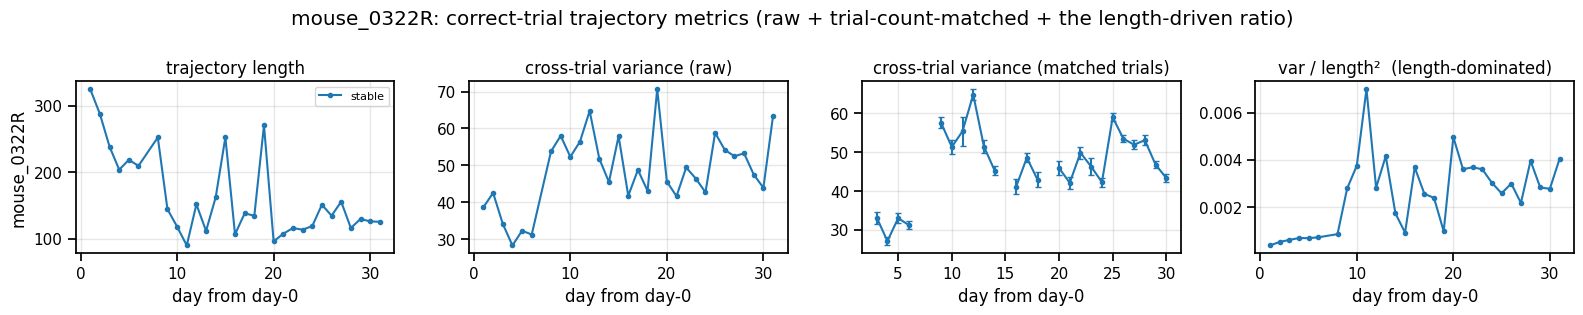

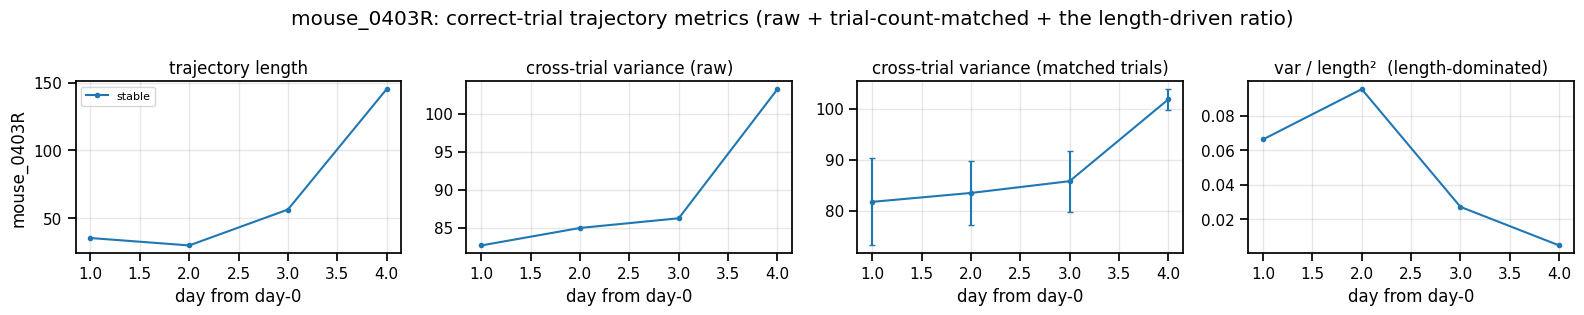

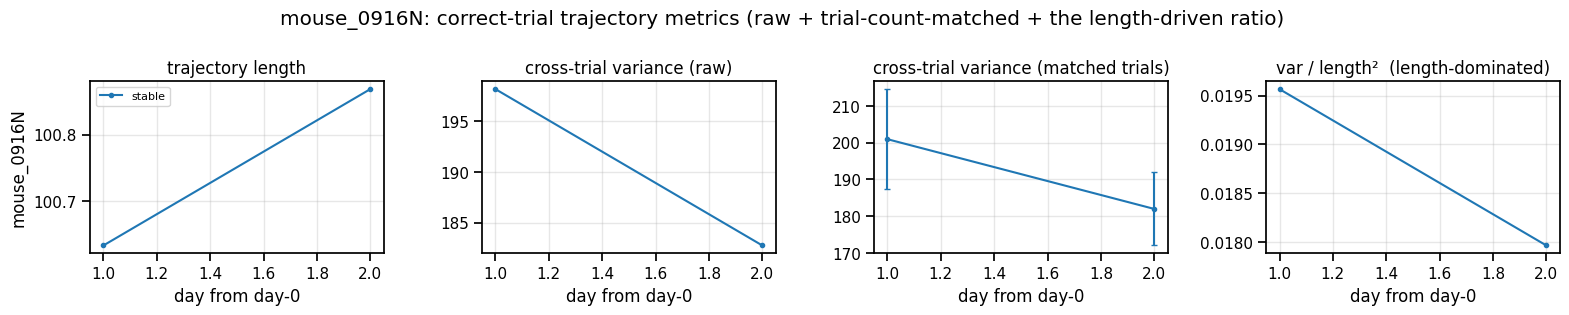

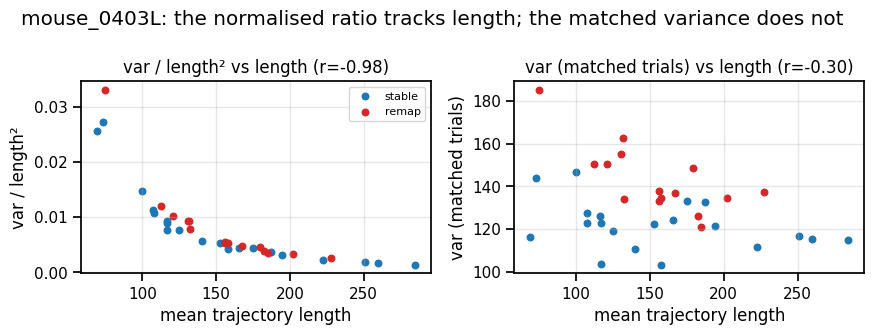

In [9]:
metrics = [("mean_length", "trajectory length"),
           ("var_raw", "cross-trial variance (raw)"),
           ("var_matched", "cross-trial variance (matched trials)"),
           ("var_per_length", "var / length²  (length-dominated)")]
for m, mo in mice.items():
    sub = traj2[traj2.mouse == m].sort_values("day_from0")
    if sub.empty: continue
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
    for ax, (col, lab) in zip(axes, metrics):
        for ph, cc in [("stable", "tab:blue"), ("remap", "tab:red")]:
            sp = sub[sub.phase == ph]
            if sp.empty or sp[col].isna().all(): continue
            if col == "var_matched" and "var_matched_sd" in sp:
                ax.errorbar(sp.day_from0, sp[col], yerr=sp.var_matched_sd, fmt="o-", ms=3, color=cc, capsize=2, label=ph)
            else:
                ax.plot(sp.day_from0, sp[col], "o-", ms=3, color=cc, label=ph)
        if mo.remap_days: ax.axvline(mo.days.index(mo.remap_days[0]) - mo.day0_idx, color="r", ls="--", lw=0.8)
        ax.set(title=lab, xlabel="day from day-0"); ax.grid(alpha=0.3)
    axes[0].set_ylabel(m); axes[0].legend(fontsize=8)
    fig.suptitle(f"{m}: correct-trial trajectory metrics (raw + trial-count-matched + the length-driven ratio)")
    fig.tight_layout(); fig.savefig(mo.out / f"{m}_traj_across_days.png", dpi=150); plt.show()

# length vs variability, directly
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, col, lab in [(axes[0], "var_per_length", "var / length²"), (axes[1], "var_matched", "var (matched trials)")]:
    for ph, cc in [("stable", "tab:blue"), ("remap", "tab:red")]:
        sp = d0[d0.phase == ph]; ax.scatter(sp.mean_length, sp[col], s=22, color=cc, label=ph)
    x = d0[["mean_length", col]].dropna(); rho, _ = spearmanr(x.mean_length, x[col])
    ax.set(xlabel="mean trajectory length", ylabel=lab, title=f"{lab} vs length (r={rho:+.2f})"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle("mouse_0403L: the normalised ratio tracks length; the matched variance does not")
fig.tight_layout(); fig.savefig(mice["mouse_0403L"].out / "traj_variance_normalisation_check.png", dpi=150); plt.show()

## 6 · Sliding-window metrics & correlation with reward rate

Within each day: matched-PR (fixed sample count, so PR–reward is not a sampling artefact), mean
trajectory length/variability, and raw + smoothed reward rate per window; then correlate each neural
measure with reward rate. (After binning, per-window sample counts are smaller, so window PR is more
sample-limited than the per-day values — trajectory length is the most robust window measure.)

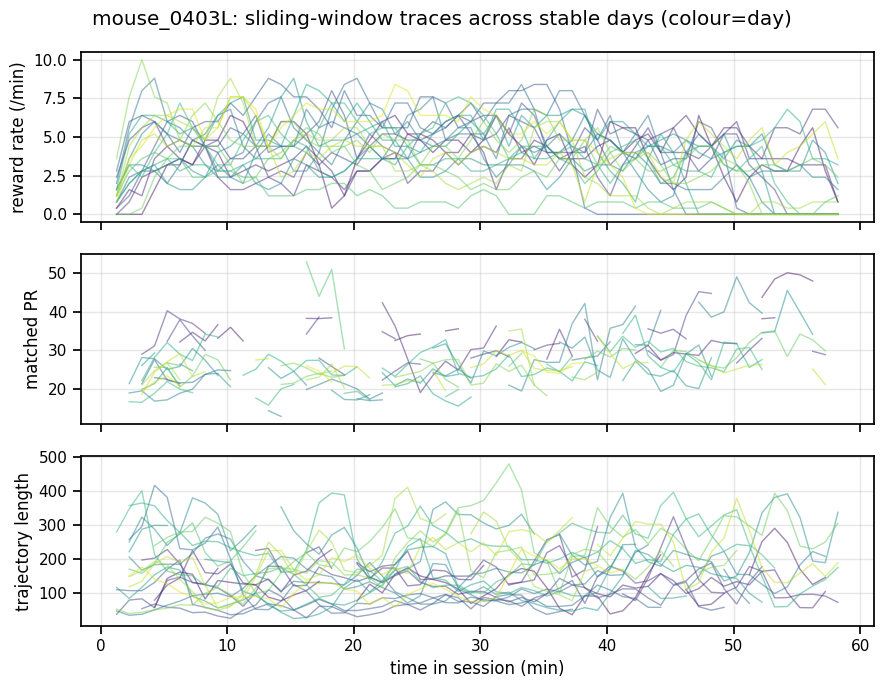

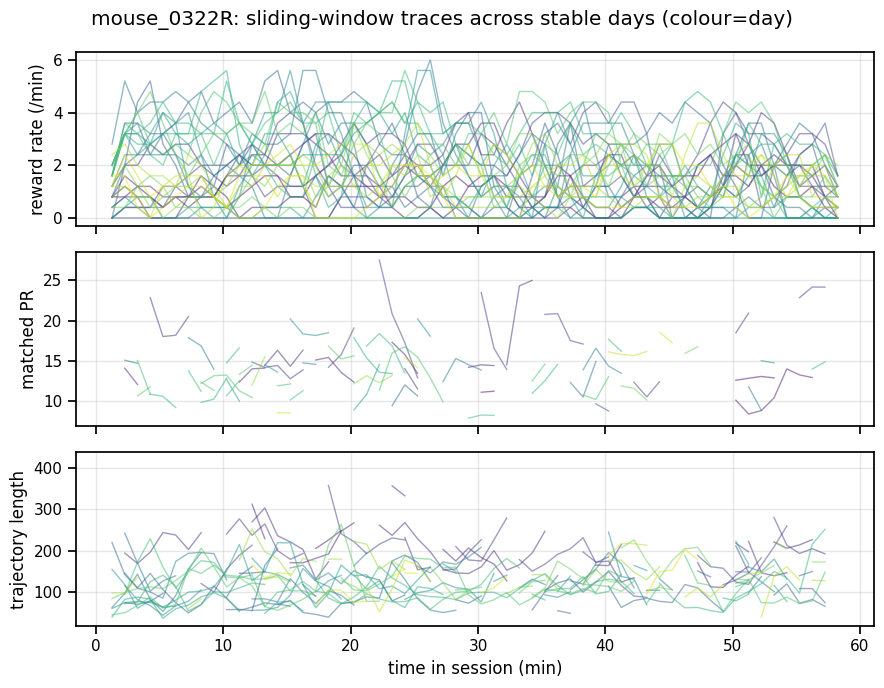

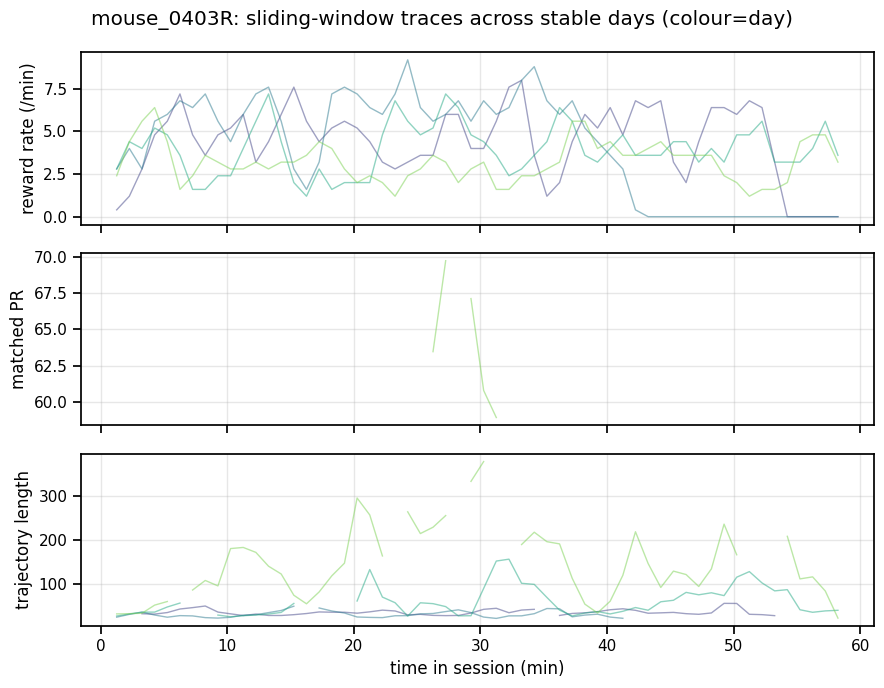

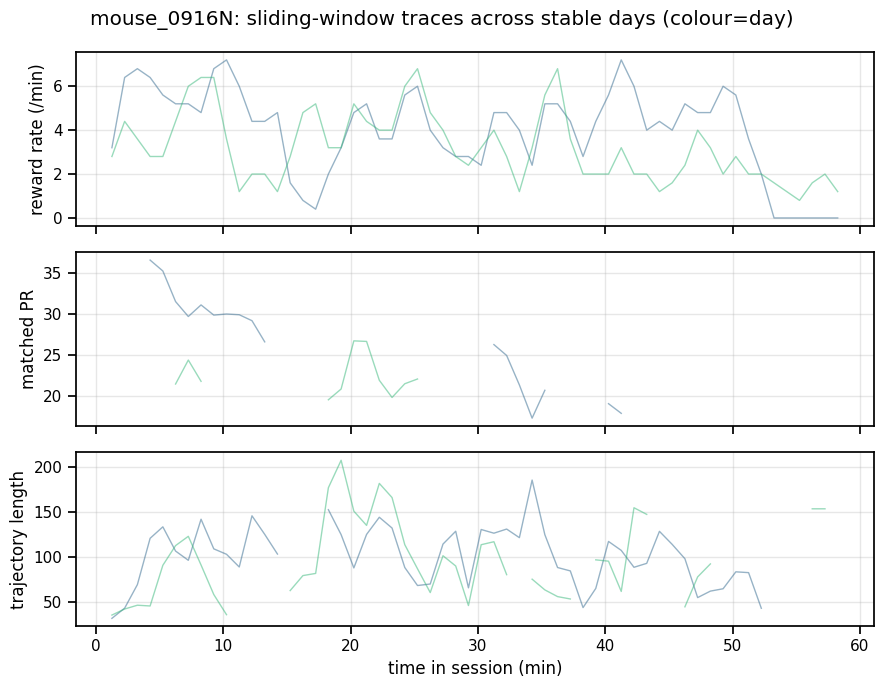

In [10]:
trace_cols = [("reward_rate","reward rate (/min)"), ("pr_matched","matched PR"), ("traj_length","trajectory length")]
for m, mo in mice.items():
    sub = win_df[(win_df.mouse == m) & (win_df.phase == "stable")]
    if sub.empty: continue
    days = sorted(sub.day.unique()); pal = sns.color_palette("viridis", len(days))
    fig, axes = plt.subplots(len(trace_cols), 1, figsize=(9, 7), sharex=True)
    for ax, (col, lab) in zip(axes, trace_cols):
        for c, day in zip(pal, days):
            s = sub[sub.day == day].sort_values("center_min"); ax.plot(s.center_min, s[col], color=c, alpha=0.5, lw=1)
        ax.set_ylabel(lab); ax.grid(alpha=0.3)
    axes[-1].set_xlabel("time in session (min)")
    fig.suptitle(f"{m}: sliding-window traces across stable days (colour=day)")
    fig.tight_layout(); fig.savefig(mo.out / f"{m}_window_traces_stable.png", dpi=150); plt.show()

,mouse,measure,reward,n,pearson_r,pearson_p,spearman_r,spearman_p
0,mouse_0403L,pr_matched,reward_rate,759,-0.265,0.000,-0.229,0.000
1,mouse_0403L,pr_matched,reward_rate_smooth,759,-0.267,0.000,-0.232,0.000
2,mouse_0403L,traj_length,reward_rate,1849,-0.644,0.000,-0.655,0.000
3,mouse_0403L,traj_length,reward_rate_smooth,1849,-0.667,0.000,-0.684,0.000
4,mouse_0403L,traj_var,reward_rate,1849,0.396,0.000,0.586,0.000
5,mouse_0403L,traj_var,reward_rate_smooth,1849,0.423,0.000,0.616,0.000
6,mouse_0322R,pr_matched,reward_rate,227,0.115,0.083,0.103,0.122
7,mouse_0322R,pr_matched,reward_rate_smooth,227,0.076,0.251,0.081,0.224
8,mouse_0322R,traj_length,reward_rate,726,-0.394,0.000,-0.387,0.000
9,mouse_0322R,traj_length,reward_rate_smooth,726,-0.373,0.000,-0.366,0.000


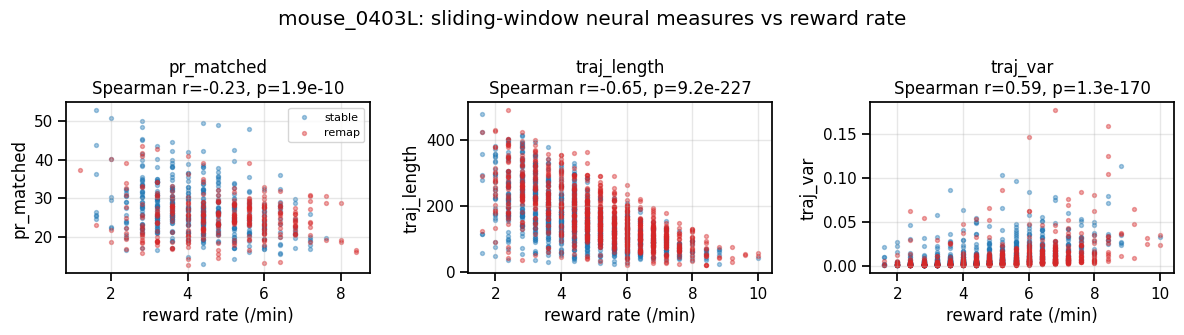

In [11]:
neural_measures = ["pr_matched", "traj_length", "traj_var"]
corr_rows = []
for m in MICE:
    sub = win_df[win_df.mouse == m]
    for nm in neural_measures:
        for rr in ["reward_rate", "reward_rate_smooth"]:
            d = sub[[nm, rr]].dropna()
            if len(d) < 10: continue
            pr_r, pr_p = pearsonr(d[nm], d[rr]); sp_r, sp_p = spearmanr(d[nm], d[rr])
            corr_rows.append(dict(mouse=m, measure=nm, reward=rr, n=len(d),
                                  pearson_r=pr_r, pearson_p=pr_p, spearman_r=sp_r, spearman_p=sp_p))
corr_df = pd.DataFrame(corr_rows); display(corr_df.round(3))

m = "mouse_0403L"; sub = win_df[win_df.mouse == m]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, nm in zip(axes, neural_measures):
    d = sub[[nm, "reward_rate", "phase"]].dropna()
    for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
        dd = d[d.phase == ph]; ax.scatter(dd["reward_rate"], dd[nm], s=8, alpha=0.4, color=cc, label=ph)
    if len(d) >= 10:
        r, p = spearmanr(d[nm], d["reward_rate"]); ax.set_title(f"{nm}\nSpearman r={r:.2f}, p={p:.1e}")
    ax.set_xlabel("reward rate (/min)"); ax.set_ylabel(nm); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle(f"{m}: sliding-window neural measures vs reward rate")
fig.tight_layout(); fig.savefig(mice[m].out / f"{m}_neural_vs_reward.png", dpi=150); plt.show()

## 7 · Manifold alignment across days

`alignment_to_ref` = subspace alignment index (mean cos² principal angles) between each day's correct
subspace and the first day's, from the single pass.

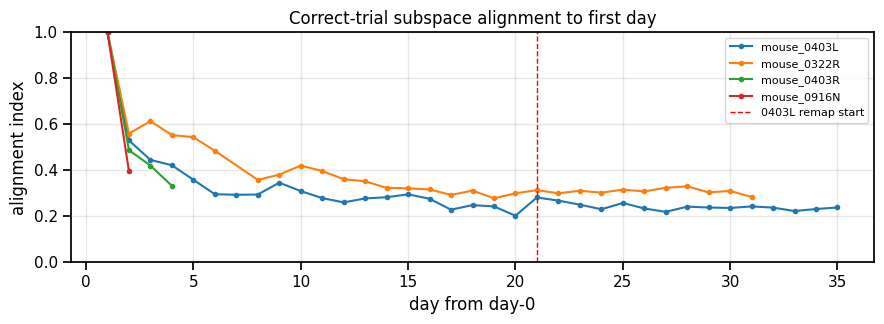

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for m in MICE:
    s = traj_df[traj_df.mouse == m].sort_values("day_from0")
    if s.empty: continue
    ax.plot(s.day_from0, s.alignment_to_ref, "o-", ms=3, label=m)
mo0 = mice["mouse_0403L"]
if mo0.remap_days:
    ax.axvline(mo0.days.index(mo0.remap_days[0]) - mo0.day0_idx, color="r", ls="--", lw=1, label="0403L remap start")
ax.set(title="Correct-trial subspace alignment to first day", xlabel="day from day-0",
       ylabel="alignment index", ylim=(0, 1)); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUTPUT_ROOT / "alignment_across_days.png", dpi=150); plt.show()

## 8 · FA-CV dimensionality (proposal's method) — optional

Set `RUN_FA_CV = True` in the config cell and re-run Section 2. Held-out FA log-likelihood keeps rising
to the grid edge on this data (effective dim ≥ 50).

In [13]:
if RUN_FA_CV and not fa_df.empty:
    display(fa_df.groupby(["mouse","condition"]).agg(best_dim_median=("best_dim","median"),
            frac_edge=("best_is_edge","mean")).reset_index())
    for m, mo in mice.items():
        for cname in FA_CONDITIONS:
            s0 = fa_df[(fa_df.mouse == m) & (fa_df.condition == cname)]
            if s0.empty: continue
            fig, ax = plt.subplots(figsize=(6.5, 3.4)); days = sorted(s0.day.unique())
            for c, day in zip(sns.color_palette("viridis", len(days)), days):
                s = s0[s0.day == day].sort_values("dim"); ax.plot(s.dim, s.mean_ll, "-", color=c, alpha=0.7, lw=1)
            ax.set(title=f"{m} · {cname}: FA-CV held-out LL (colour=day)", xlabel="latent dim", ylabel="held-out LL"); ax.grid(alpha=0.3)
            fig.tight_layout(); fig.savefig(mo.out / f"{m}_facv_{cname}.png", dpi=150); plt.show()
else:
    print("RUN_FA_CV is False. Enable it in the config cell and re-run Section 2.")

RUN_FA_CV is False. Enable it in the config cell and re-run Section 2.


## 9 · Remapping: intuitive vs new axis (`mouse_0403L`)

Correct trials split by axis label (2 = intuitive, 3 = new). Per remapping day: matched-PR, trajectory
length/variability per axis; plus alignment and cross variance-capture between the two axes' subspaces.

In [14]:
AXIS_MATCH_N = 40            # fixed trial count for the per-axis variability estimate

def compute_remap_tables(mo):
    remap_idx0 = mo.days.index(mo.remap_days[0])
    rows_axis, rows_day = [], []
    for day in tqdm(mo.remap_days, desc=f"remap {mo.name}"):
        X, trials, rew, T, _ = preprocess_day(mo, day)
        dfrom = mo.days.index(day) - remap_idx0
        subs = {}
        for axis, fac in [("intuitive", 2.0), ("new", 3.0)]:
            ivs = na.correct_trial_intervals(trials, T, factor=fac)
            if len(ivs) < MIN_TRIALS: subs[axis] = None; continue
            Xc = na.intervals_to_matrix(X, ivs); sub = na.fit_subspace(Xc, K_PC); subs[axis] = (sub, Xc)
            pr_m, _ = na.participation_ratio_matched(Xc, MATCHED_N_SAMPLES_AXIS, n_boot=MATCHED_N_BOOT)
            trj = [sub.project(t) for t in na.intervals_to_trajectories(X, ivs)]
            ts = na.trajectory_stats(trj, n_resample=N_RESAMPLE)
            vmA, _ = na.trajectory_variance_matched(trj, AXIS_MATCH_N, n_resample=N_RESAMPLE, n_boot=8)
            rows_axis.append(dict(mouse=mo.name, day=day, remap_day=dfrom, axis=axis, n_trials=len(ivs),
                                  pr_matched=pr_m, mean_length=ts.mean_length, var_raw=ts.var_raw,
                                  var_matched=vmA, var_per_length=ts.var_per_length))
        if subs.get("intuitive") and subs.get("new"):
            (si, Xi), (sn, Xn) = subs["intuitive"], subs["new"]
            rows_day.append(dict(mouse=mo.name, day=day, remap_day=dfrom, alignment=na.alignment_index(si, sn),
                                 mean_principal_angle=float(np.mean(na.principal_angles_deg(si, sn))),
                                 new_in_intuitive=na.variance_capture(si, Xn), intuitive_in_new=na.variance_capture(sn, Xi)))
    return pd.DataFrame(rows_axis), pd.DataFrame(rows_day)

mo = mice["mouse_0403L"]
fa_ax, fp_ax = mo.out / f"remap_axis_table_{PARAM_TAG}_v2.csv", mo.out / f"remap_day_table_{PARAM_TAG}_v2.csv"
if USE_CACHE and fa_ax.exists() and fp_ax.exists():
    remap_axis_df, remap_day_df = pd.read_csv(fa_ax), pd.read_csv(fp_ax)
else:
    remap_axis_df, remap_day_df = compute_remap_tables(mo)
    remap_axis_df.to_csv(fa_ax, index=False); remap_day_df.to_csv(fp_ax, index=False)
display(remap_day_df.round(3)); remap_axis_df.head()

,mouse,day,remap_day,alignment,mean_principal_angle,new_in_intuitive,intuitive_in_new
0,mouse_0403L,20230725,0,0.339,57.162,0.165,0.223
1,mouse_0403L,20230726,1,0.296,60.080,0.157,0.211
2,mouse_0403L,20230727,2,0.304,59.840,0.174,0.210
3,mouse_0403L,20230728,3,0.317,59.116,0.180,0.224
4,mouse_0403L,20230729,4,0.340,57.538,0.177,0.223
5,mouse_0403L,20230730,5,0.340,57.347,0.206,0.221
6,mouse_0403L,20230731,6,0.285,60.560,0.206,0.227
7,mouse_0403L,20230801,7,0.323,58.208,0.198,0.192
8,mouse_0403L,20230802,8,0.316,58.799,0.185,0.214
9,mouse_0403L,20230803,9,0.262,63.178,0.156,0.184


,mouse,day,remap_day,axis,n_trials,pr_matched,mean_length,var_raw,var_matched,var_per_length
0,mouse_0403L,20230725,0,intuitive,98,32.452723,77.939565,145.261581,140.530199,0.023913
1,mouse_0403L,20230725,0,new,135,64.076264,340.724206,108.666244,108.604065,0.000936
2,mouse_0403L,20230726,1,intuitive,87,26.940943,98.926214,152.154696,148.896213,0.015548
3,mouse_0403L,20230726,1,new,209,51.585168,217.277690,113.232442,115.998089,0.002399
4,mouse_0403L,20230727,2,intuitive,91,27.567352,148.860129,172.755218,169.562093,0.007796


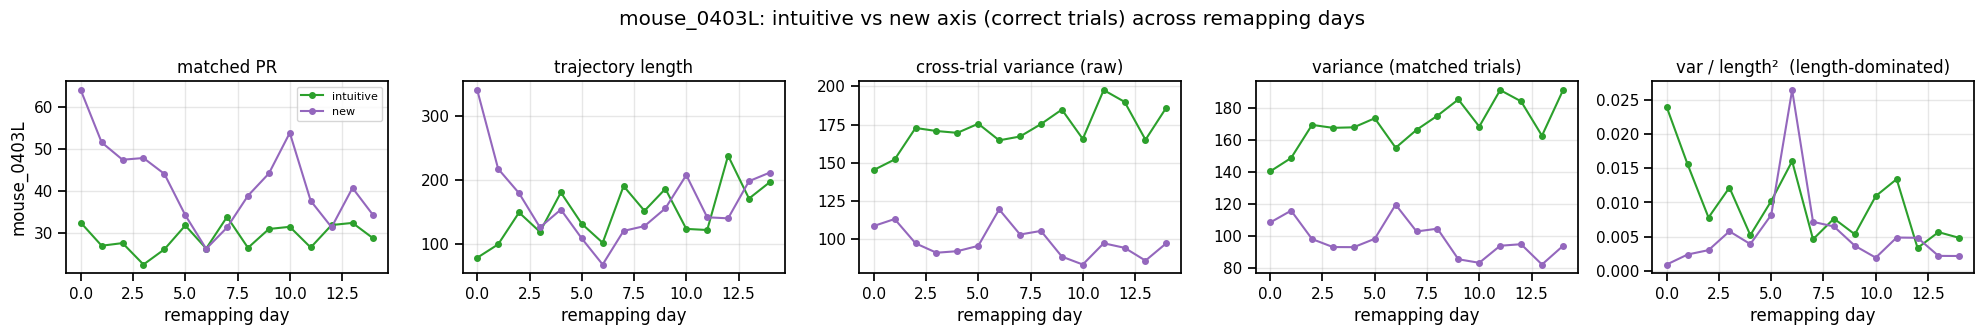

  mean_length     intuitive=  148.951  new=  166.151   ratio new/int=1.12
  var_raw         intuitive=  172.136  new=   98.263   ratio new/int=0.57
  var_matched     intuitive=  169.921  new=   97.969   ratio new/int=0.58
  var_per_length  intuitive=    0.010  new=    0.006   ratio new/int=0.57
  -> averaged over days the two axes have SIMILAR mean lengths (ratio ~1.1), and the raw and
     trial-matched variances agree closely (~0.57 vs ~0.58), so the lower variability of new-axis
     trajectories here is real, not a length artefact. The length confound bites ACROSS DAYS
     (var_per_length vs length r=-0.98), which is why var_raw / var_matched are the ones to read.


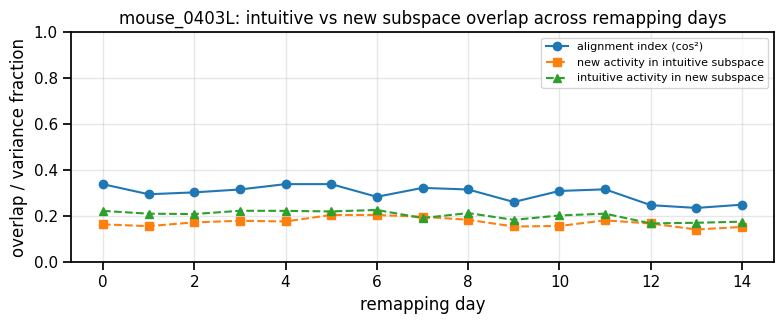

In [15]:
mo = mice["mouse_0403L"]
axis_metrics = [("pr_matched", "matched PR"), ("mean_length", "trajectory length"),
                ("var_raw", "cross-trial variance (raw)"), ("var_matched", "variance (matched trials)"),
                ("var_per_length", "var / length²  (length-dominated)")]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.4))
for ax, (col, lab) in zip(axes, axis_metrics):
    for axis, cc in [("intuitive","tab:green"), ("new","tab:purple")]:
        s = remap_axis_df[remap_axis_df.axis == axis].sort_values("remap_day")
        ax.plot(s.remap_day, s[col], "o-", ms=4, color=cc, label=axis)
    ax.set(title=lab, xlabel="remapping day"); ax.grid(alpha=0.3)
axes[0].set_ylabel("mouse_0403L"); axes[0].legend(fontsize=8)
fig.suptitle("mouse_0403L: intuitive vs new axis (correct trials) across remapping days")
fig.tight_layout(); fig.savefig(mo.out / "remap_axis_metrics.png", dpi=150); plt.show()
for c in ["mean_length", "var_raw", "var_matched", "var_per_length"]:
    gi = remap_axis_df[remap_axis_df.axis == "intuitive"][c].dropna()
    gn = remap_axis_df[remap_axis_df.axis == "new"][c].dropna()
    print(f"  {c:15s} intuitive={gi.mean():9.3f}  new={gn.mean():9.3f}   ratio new/int={gn.mean()/gi.mean():.2f}")
print("  -> averaged over days the two axes have SIMILAR mean lengths (ratio ~1.1), and the raw and")
print("     trial-matched variances agree closely (~0.57 vs ~0.58), so the lower variability of new-axis")
print("     trajectories here is real, not a length artefact. The length confound bites ACROSS DAYS")
print("     (var_per_length vs length r=-0.98), which is why var_raw / var_matched are the ones to read.")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(remap_day_df.remap_day, remap_day_df.alignment, "o-", label="alignment index (cos²)")
ax.plot(remap_day_df.remap_day, remap_day_df.new_in_intuitive, "s--", label="new activity in intuitive subspace")
ax.plot(remap_day_df.remap_day, remap_day_df.intuitive_in_new, "^--", label="intuitive activity in new subspace")
ax.set(title="mouse_0403L: intuitive vs new subspace overlap across remapping days",
       xlabel="remapping day", ylabel="overlap / variance fraction", ylim=(0, 1)); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(mo.out / "remap_subspace_overlap.png", dpi=150); plt.show()

## 10 · One trajectory or two? — mean trajectories in a common subspace (`mouse_0403L`)

Intuitive vs new mean correct-trial trajectories projected into a common (both-axes) subspace, for an
early, middle and late remapping day. Distinct endpoints that stay separated → two trajectories;
converging/merging → one shared trajectory.

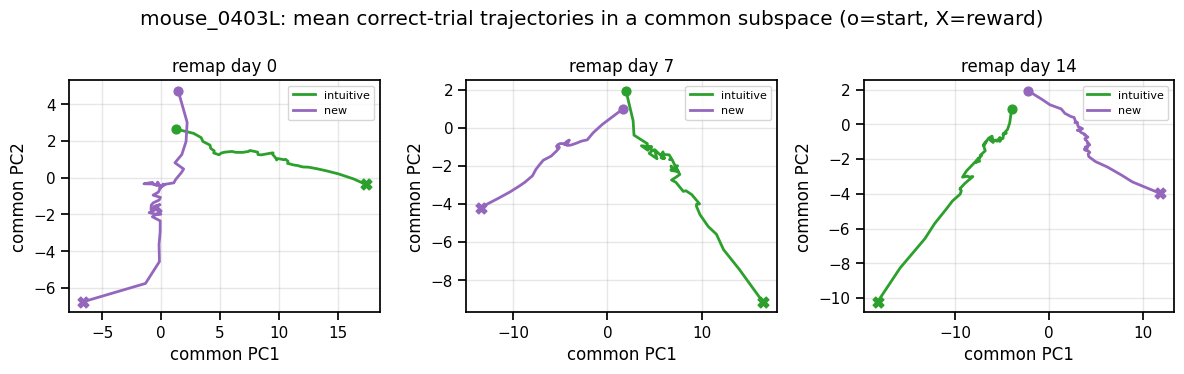

In [16]:
mo = mice["mouse_0403L"]
sel = [mo.remap_days[0], mo.remap_days[len(mo.remap_days)//2], mo.remap_days[-1]]
remap_idx0 = mo.days.index(mo.remap_days[0])
fig, axes = plt.subplots(1, len(sel), figsize=(4*len(sel), 3.8))
if len(sel) == 1: axes = [axes]
for ax, day in zip(axes, sel):
    X, trials, rew, T, _ = preprocess_day(mo, day)
    iv_i = na.correct_trial_intervals(trials, T, factor=2.0); iv_n = na.correct_trial_intervals(trials, T, factor=3.0)
    common = na.fit_subspace(na.intervals_to_matrix(X, iv_i + iv_n), K_PC)
    for ivs, cc, lab in [(iv_i, "tab:green", "intuitive"), (iv_n, "tab:purple", "new")]:
        trajs = [common.project(t)[:, :2] for t in na.intervals_to_trajectories(X, ivs)]
        R = np.stack([na.resample_trajectory(t, N_RESAMPLE) for t in trajs if t.shape[0] >= 2], 0); mtraj = R.mean(0)
        ax.plot(mtraj[:, 0], mtraj[:, 1], color=cc, lw=2, label=lab)
        ax.scatter(*mtraj[0], color=cc, marker="o", s=40, zorder=3); ax.scatter(*mtraj[-1], color=cc, marker="X", s=60, zorder=3)
    ax.set(title=f"remap day {mo.days.index(day)-remap_idx0}", xlabel="common PC1", ylabel="common PC2"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle("mouse_0403L: mean correct-trial trajectories in a common subspace (o=start, X=reward)")
fig.tight_layout(); fig.savefig(mo.out / "remap_common_trajectories.png", dpi=150); plt.show()

## 11 · Exploration trajectories in PC pairs — how the animal searches for the new axis

The central question: **how does the population explore to find the new decoder axis after the
uncued rotation, and how is the intuitive axis found in the first place?** We plot single-trial
trajectories as pairwise 2-D PC projections (PC1–PC2, PC1–PC3, PC2–PC3, …) — not 3-D — for the first
few PCs, in a **common per-day subspace fit on all correct+incorrect trials of that day**.

`plot_pc_pairs` is a general helper (edit freely). Each group of trajectories is drawn either in a
fixed colour (e.g. correct=blue, incorrect=red) or coloured by **trial order** (viridis, early→late)
to reveal how the search evolves within a session.

In [17]:
def project_trials(X, intervals, subspace):
    return [subspace.project(t) for t in na.intervals_to_trajectories(X, intervals)]

def mean_trajectory(trajs, n_resample=N_RESAMPLE):
    trajs = [t for t in trajs if t.shape[0] >= 2]
    if not trajs: return None
    return np.stack([na.resample_trajectory(t, n_resample) for t in trajs], 0).mean(0)

def epoch_mean_trajectories(trajs, n_epochs=6, n_resample=N_RESAMPLE):
    # split trajs (kept in trial order) into n_epochs blocks; mean trajectory of each block
    trajs = [t for t in trajs if t.shape[0] >= 2]
    if not trajs: return []
    out = []
    for g in np.array_split(np.arange(len(trajs)), min(n_epochs, len(trajs))):
        if len(g) == 0: continue
        out.append(np.stack([na.resample_trajectory(trajs[i], n_resample) for i in g], 0).mean(0))
    return out

def plot_pc_pairs(groups, pcs=(0, 1, 2, 3), title="", ncol=3, savepath=None, figsize_scale=3.6):
    # Each group dict: trajs (list of (t,>=maxpc)); either color=<c> or cmap=<name> (colour by order);
    # optional label, lw, alpha, markers (mark start 'o' / end 'X').
    pairs = [(pcs[i], pcs[j]) for i in range(len(pcs)) for j in range(i + 1, len(pcs))]
    nrow = int(np.ceil(len(pairs) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(figsize_scale * ncol, figsize_scale * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, (a, b) in zip(axes, pairs):
        for g in groups:
            trs = g["trajs"]; glw = g.get("lw", 2.0); gal = g.get("alpha", 0.9); mk = g.get("markers", False)
            cmap = plt.get_cmap(g["cmap"]) if "cmap" in g else None
            n = max(len(trs) - 1, 1)
            for k, tr in enumerate(trs):
                col = cmap(k / n) if cmap is not None else g["color"]
                ax.plot(tr[:, a], tr[:, b], color=col, lw=glw, alpha=gal,
                        label=(g.get("label") if (k == 0 and cmap is None) else None))
                if mk and tr.shape[0] > 1:
                    ax.scatter(tr[0, a], tr[0, b], color=col, marker="o", s=22, zorder=3, edgecolor="k", linewidth=0.3)
                    ax.scatter(tr[-1, a], tr[-1, b], color=col, marker="X", s=34, zorder=3, edgecolor="k", linewidth=0.3)
        ax.set_xlabel(f"PC{a+1}"); ax.set_ylabel(f"PC{b+1}"); ax.grid(alpha=0.25)
    for ax in axes[len(pairs):]: ax.axis("off")
    if any(("label" in g and "cmap" not in g) for g in groups):
        axes[0].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    if savepath: fig.savefig(savepath, dpi=150)
    plt.show()

print("plot_pc_pairs ready")

plot_pc_pairs ready


### 11a · First remapping day: searching for the new axis

To see the *search* without a hairball, post-rotation correct (and, separately, incorrect) trials are
split into `N_EPOCH` blocks **in trial order** and each block's **mean trajectory** is drawn, coloured
dark→bright (early→late). The intuitive-axis mean (green) is the pre-rotation reference (o = start,
X = end). If the population searches then settles, the epoch means should start displaced/scattered
and progressively migrate to a consistent new-axis path. A faint layer of individual trials shows the
underlying spread.

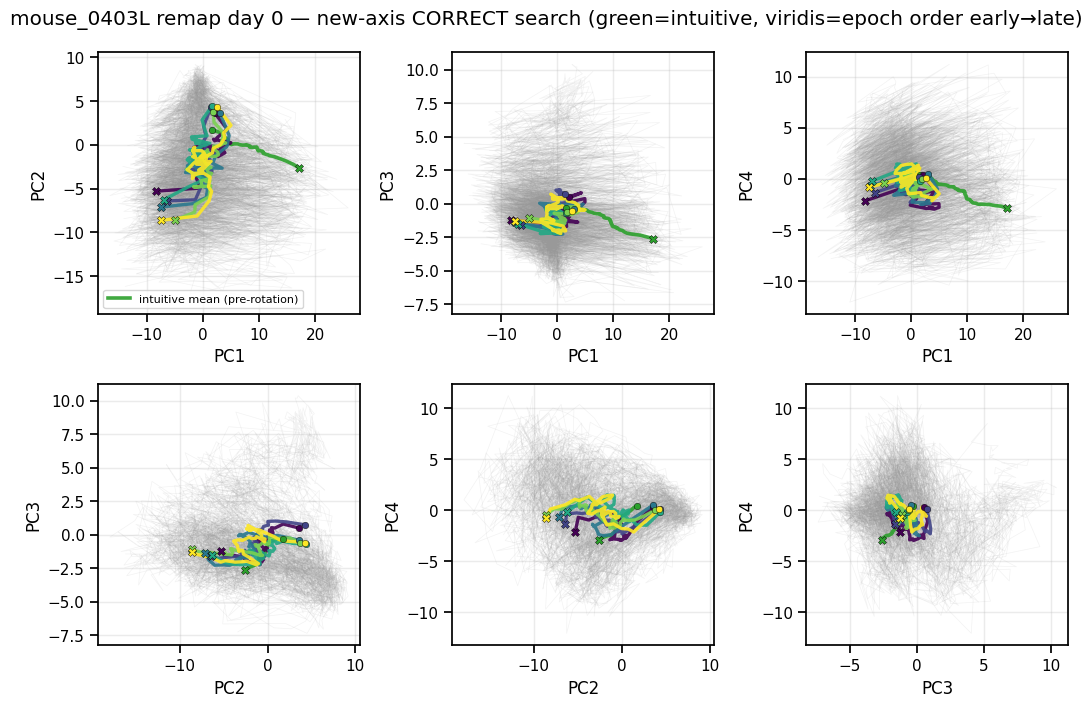

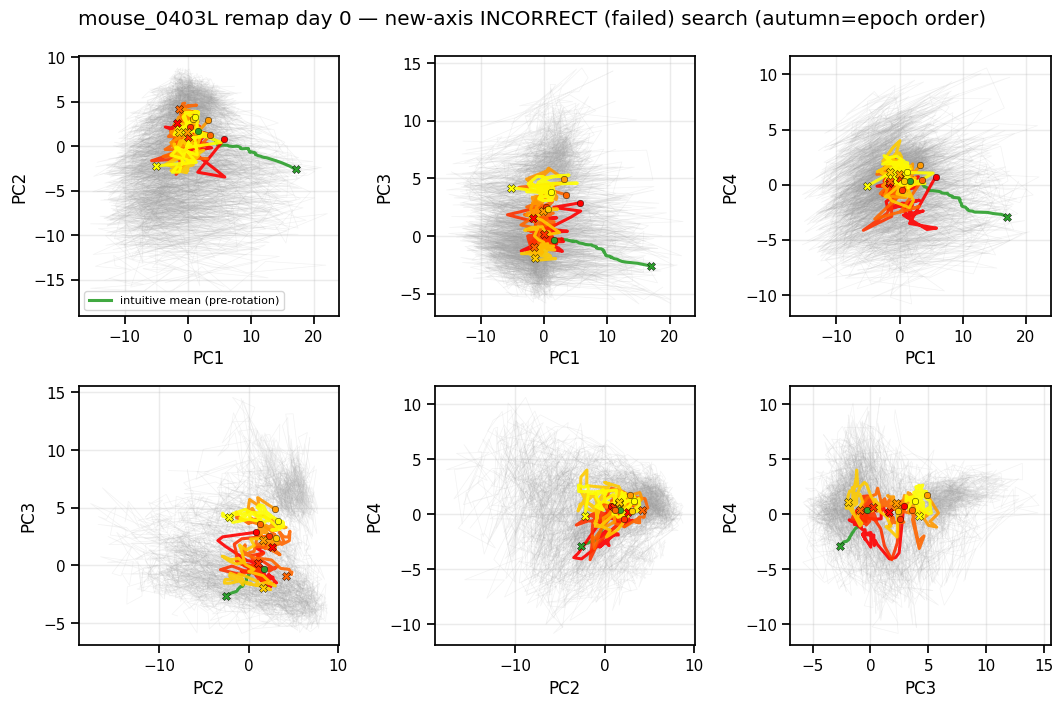

In [18]:
mo = mice["mouse_0403L"]; PCS = (0, 1, 2, 3); N_EPOCH = 6
day = mo.remap_days[0]
X, trials, rew, T, _ = preprocess_day(mo, day)
rframe = na.remapping_start_frame(trials)
iv_pre = na.correct_trial_intervals(trials, T, factor=2.0)                       # intuitive (pre-rotation)
iv_post_c = na.correct_trial_intervals(trials, T, factor=3.0)                    # new-axis correct
allmiss = na.incorrect_trial_intervals(trials, T, window_sec=INCORRECT_WINDOW_SEC, sr=SR_BINNED, factor=3.0)
iv_post_i = [iv for iv in allmiss if iv[0] >= (rframe or 0)]                     # new-axis incorrect

common = na.fit_subspace(na.intervals_to_matrix(X, iv_pre + iv_post_c + iv_post_i), max(PCS)+1)
pre_mean = mean_trajectory(project_trials(X, iv_pre, common))
post_c_all = project_trials(X, iv_post_c, common)
post_i_all = project_trials(X, iv_post_i, common)

plot_pc_pairs(
    [dict(trajs=post_c_all, color="0.6", lw=0.5, alpha=0.12),                    # faint individual trials
     dict(trajs=[pre_mean], color="tab:green", label="intuitive mean (pre-rotation)", lw=2.6, markers=True),
     dict(trajs=epoch_mean_trajectories(post_c_all, N_EPOCH), cmap="viridis", lw=2.4, markers=True)],
    pcs=PCS, title=f"mouse_0403L remap day 0 — new-axis CORRECT search (green=intuitive, viridis=epoch order early→late)",
    savepath=mo.out / "explore_remapday0_correct.png")

plot_pc_pairs(
    [dict(trajs=post_i_all, color="0.6", lw=0.5, alpha=0.12),
     dict(trajs=[pre_mean], color="tab:green", label="intuitive mean (pre-rotation)", lw=2.2, markers=True),
     dict(trajs=epoch_mean_trajectories(post_i_all, N_EPOCH), cmap="autumn", lw=2.2, markers=True)],
    pcs=PCS, title="mouse_0403L remap day 0 — new-axis INCORRECT (failed) search (autumn=epoch order)",
    savepath=mo.out / "explore_remapday0_incorrect.png")

### 11b · Learning across days: how each axis's trajectory consolidates

**What data define this PCA space?** `dayset_mean_trajectories` fits **one** subspace on
**correct-trial samples only**: for each day it takes `na.correct_trial_intervals(...)` (every binned
timepoint from trial start to reward, for *successful* trials of the requested `factor`), subsamples
≤ `cap_per_day` = 1500 bins per day, concatenates across the whole day-set and fits `k` PCs on that
pooled matrix. No incorrect trials, no inter-trial/baseline data, no reward-consumption periods enter
the fit. The new-axis panel therefore uses **new-axis (factor 3) correct trials pooled over all 15
remapping days**; the stable panel uses all correct trials pooled over the stable-control days. Each
day's mean trajectory is then projected into that common space.

One mean correct trajectory per day, coloured by day (dark→bright = early→late). Left question — *how
the intuitive axis is found in the first place*: over the **stable-control days** the mean path should
migrate from an exploratory shape to a consolidated one. Right question — *how the new axis emerges*:
over the **remapping days** the new-axis (factor 3) mean path should converge similarly.

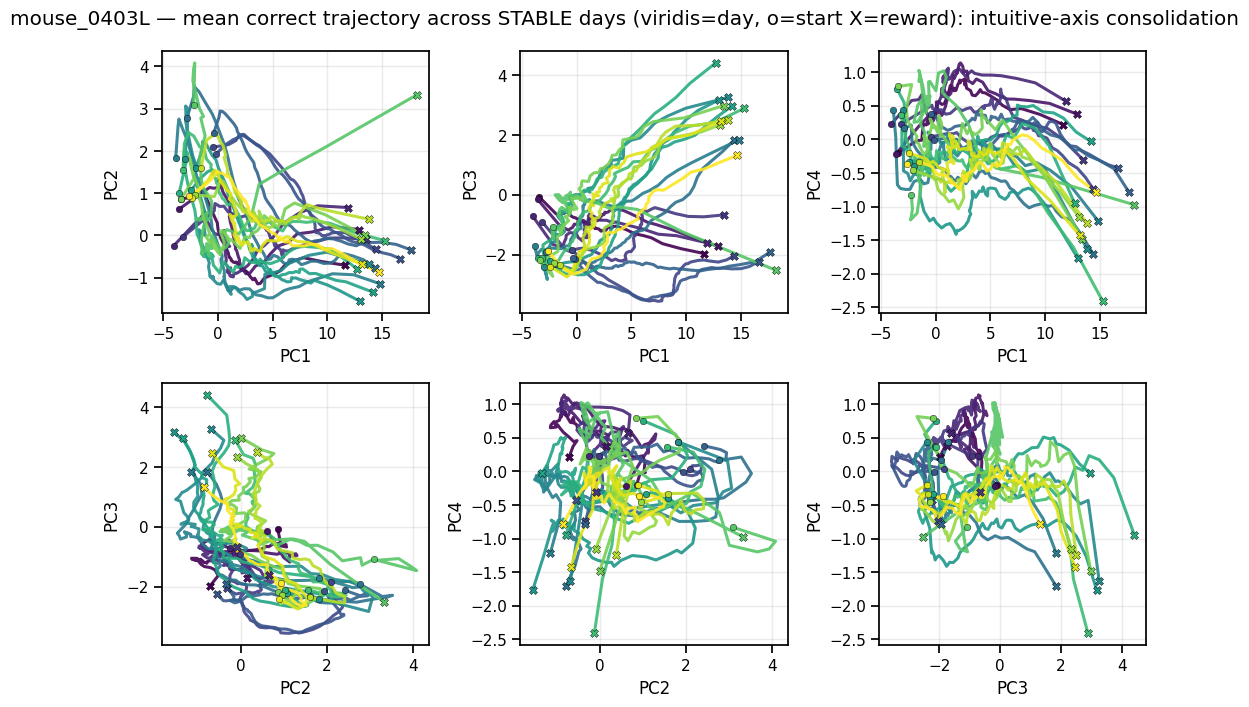

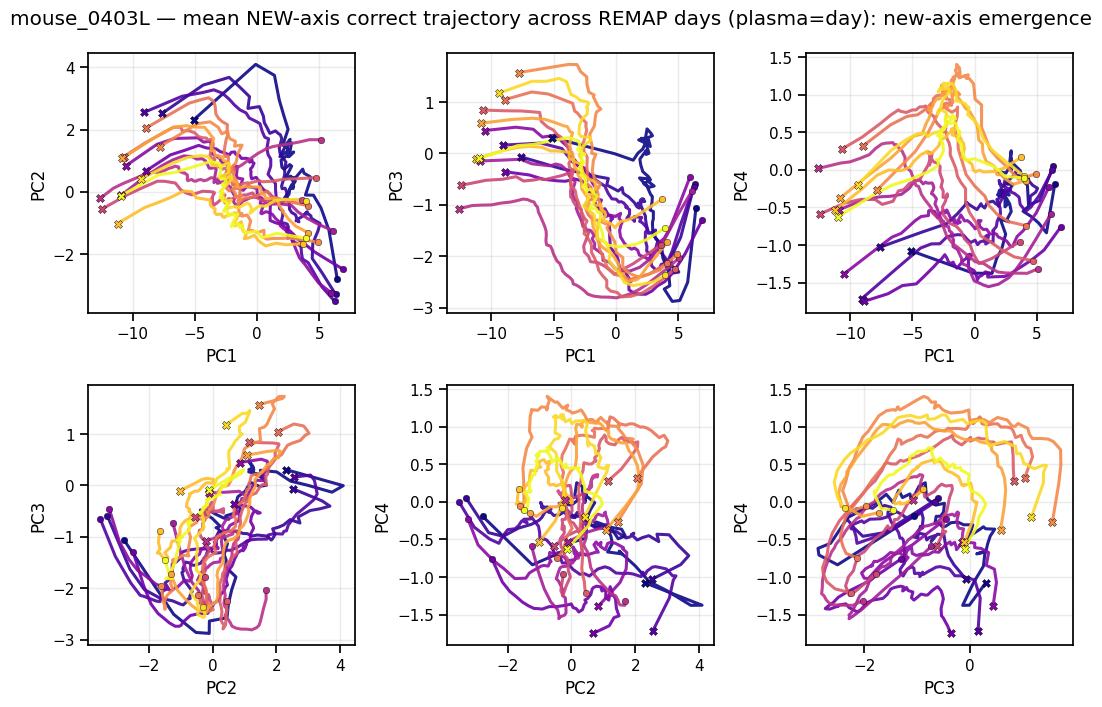

In [19]:
mo = mice["mouse_0403L"]; PCS = (0, 1, 2, 3)
def dayset_mean_trajectories(days_list, factor=None, k=4, cap_per_day=1500):
    data = []
    for day in days_list:
        X, trials, rew, T, _ = preprocess_day(mo, day)
        ivc = na.correct_trial_intervals(trials, T, factor=factor)
        if len(ivc) >= 2: data.append((X, ivc))
    if not data: return []
    common = na.fit_subspace(np.concatenate([na.subsample_rows(na.intervals_to_matrix(X, ivc), cap_per_day)
                                             for X, ivc in data], 0), k)
    means = [mean_trajectory([common.project(t) for t in na.intervals_to_trajectories(X, ivc)]) for X, ivc in data]
    return [m for m in means if m is not None]

stable_means = dayset_mean_trajectories(mo.stable_days, factor=None, k=max(PCS)+1)
plot_pc_pairs([dict(trajs=stable_means, cmap="viridis", lw=2.2, markers=True)],
              pcs=PCS, title="mouse_0403L — mean correct trajectory across STABLE days (viridis=day, o=start X=reward): intuitive-axis consolidation",
              savepath=mo.out / "explore_stable_daymeans.png")

new_means = dayset_mean_trajectories(mo.remap_days, factor=3.0, k=max(PCS)+1)
plot_pc_pairs([dict(trajs=new_means, cmap="plasma", lw=2.2, markers=True)],
              pcs=PCS, title="mouse_0403L — mean NEW-axis correct trajectory across REMAP days (plasma=day): new-axis emergence",
              savepath=mo.out / "explore_remap_daymeans.png")

### 11b-ii · Is the secondary pattern in the new-axis subspace the *intuitive* solution?

In the panel above the early-day trajectories run mostly along **PC2** and later days rotate toward
**PC1**. That implies a second strong coordinated pattern inside the new-axis correct-trial subspace
that fades with training. Direct test: define two solution directions from the neural data of each
remapping day — `u_int` (from the pre-rotation intuitive-block correct endpoints) and `u_new` (from the
late new-block correct endpoints), both relative to that day's inter-trial mean — and ask how much of
the **new-axis correct-trial activity** projects onto each, and whether the intuitive component
declines across days. A random unit direction gives the chance level.

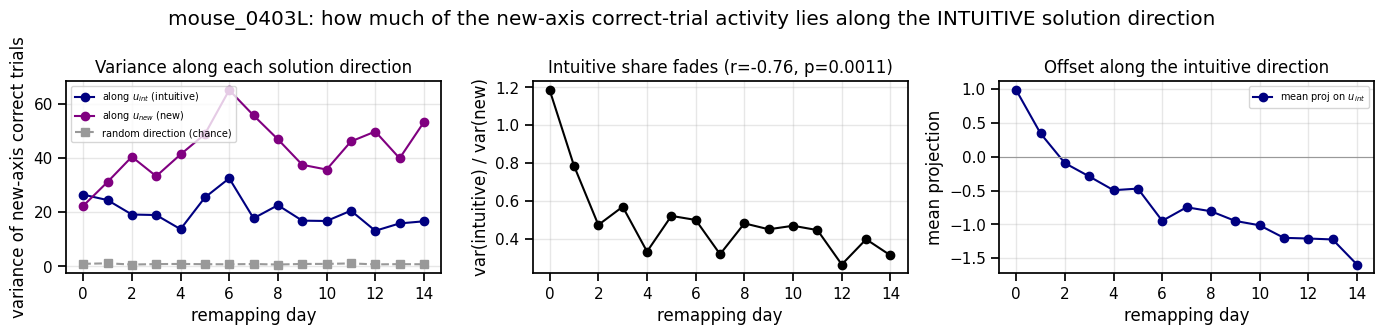

  var_int vs remap day: Spearman r=-0.59 p=0.0208
  var_new vs remap day: Spearman r=+0.46 p=0.0867
  var_int/var_new: first 3 days=0.82  last 5 days=0.38
  mean projection on u_int: day 0=+0.98 -> last day=-1.59
  chance variance (random direction) = 0.88, so both components are far above chance.



  alignment of the pooled new-axis correct-trial PCs (the space used in 11b):
    PC1: |cos with u_int|=0.561   |cos with u_new|=0.867
    PC2: |cos with u_int|=0.438   |cos with u_new|=0.315
    PC3: |cos with u_int|=0.213   |cos with u_new|=0.049
    PC4: |cos with u_int|=0.078   |cos with u_new|=0.147
    chance |cos| for a random direction ~ 0.046
  -> PC1 is dominated by the NEW direction, while PC2 aligns more with the INTUITIVE direction
     than with the new one: the secondary pattern you spotted is largely the old solution.


In [20]:
def intuitive_component_rows(mo):
    rows = []
    for di, day in enumerate(tqdm(mo.remap_days, desc="intuitive component")):
        X, trials, rew, T, _ = preprocess_day(mo, day)
        blocks = na.segment_factor_blocks(trials)
        if len(blocks) != 3: continue
        b_int, b_new, _ = blocks
        lab = na.label_timepoints(trials, T, sr=SR_BINNED)
        c = X[:, lab == na.STATE_ITI].mean(1)                       # inter-trial centre
        def endpoint_mean(b, half=False):
            idx = [i for i in range(b.first_trial, b.last_trial + 1)
                   if trials.success[i] == 1 and np.isfinite(trials.start[i]) and np.isfinite(trials.end[i])
                   and trials.end[i] > trials.start[i]]
            if half: idx = idx[len(idx) // 2:]
            w = max(int(round(1.0 * SR_BINNED)), 1); out = []
            for i in idx:
                st, en = max(int(round(trials.start[i])), 0), min(int(round(trials.end[i])), T)
                if en > st: out.append(X[:, max(en - w, st):en].mean(1))
            return np.mean(out, 0) if out else None
        Ti, Tn = endpoint_mean(b_int), endpoint_mean(b_new, half=True)
        if Ti is None or Tn is None: continue
        u_int = (Ti - c) / np.linalg.norm(Ti - c); u_new = (Tn - c) / np.linalg.norm(Tn - c)
        M = na.intervals_to_matrix(X, na.correct_trial_intervals(trials, T, factor=3.0)) - c
        rng = np.random.RandomState(di); q = rng.randn(X.shape[0]); q /= np.linalg.norm(q)
        rows.append(dict(remap_day=di, day=day,
                         var_int=float(np.var(M @ u_int)), var_new=float(np.var(M @ u_new)),
                         var_rand=float(np.var(M @ q)), mean_int=float(np.mean(M @ u_int)),
                         mean_new=float(np.mean(M @ u_new)), cos_int_new=float(abs(u_int @ u_new))))
    return pd.DataFrame(rows)

mo = mice["mouse_0403L"]
ic_fp = mo.out / f"intuitive_component_{PARAM_TAG}.csv"
if USE_CACHE and ic_fp.exists():
    icdf = pd.read_csv(ic_fp)
else:
    icdf = intuitive_component_rows(mo); icdf.to_csv(ic_fp, index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(icdf.remap_day, icdf.var_int, "o-", color="navy", label="along $u_{int}$ (intuitive)")
axes[0].plot(icdf.remap_day, icdf.var_new, "o-", color="purple", label="along $u_{new}$ (new)")
axes[0].plot(icdf.remap_day, icdf.var_rand, "s--", color="0.6", label="random direction (chance)")
axes[0].set(xlabel="remapping day", ylabel="variance of new-axis correct trials", title="Variance along each solution direction")
axes[0].legend(fontsize=7)
axes[1].plot(icdf.remap_day, icdf.var_int / icdf.var_new, "o-", color="k")
rho, pv = spearmanr(icdf.remap_day, icdf.var_int / icdf.var_new)
axes[1].set(xlabel="remapping day", ylabel="var(intuitive) / var(new)", title=f"Intuitive share fades (r={rho:+.2f}, p={pv:.4f})")
axes[2].plot(icdf.remap_day, icdf.mean_int, "o-", color="navy", label="mean proj on $u_{int}$")
axes[2].axhline(0, color="0.6", lw=0.8)
axes[2].set(xlabel="remapping day", ylabel="mean projection", title="Offset along the intuitive direction"); axes[2].legend(fontsize=7)
for a in axes: a.grid(alpha=0.3)
fig.suptitle("mouse_0403L: how much of the new-axis correct-trial activity lies along the INTUITIVE solution direction")
fig.tight_layout(); fig.savefig(mo.out / "intuitive_component_in_new_axis.png", dpi=150); plt.show()

for c_ in ["var_int", "var_new"]:
    rho, pv = spearmanr(icdf.remap_day, icdf[c_]); print(f"  {c_} vs remap day: Spearman r={rho:+.2f} p={pv:.4f}")
rat = icdf.var_int / icdf.var_new
print(f"  var_int/var_new: first 3 days={rat[:3].mean():.2f}  last 5 days={rat.iloc[-5:].mean():.2f}")
print(f"  mean projection on u_int: day 0={icdf.mean_int.iloc[0]:+.2f} -> last day={icdf.mean_int.iloc[-1]:+.2f}")
print(f"  chance variance (random direction) = {icdf.var_rand.mean():.2f}, so both components are far above chance.")

# how the pooled new-axis PCs align with the two solution directions
Ms, uis, uns = [], [], []
for day in mo.remap_days:
    X, trials, rew, T, _ = preprocess_day(mo, day)
    blocks = na.segment_factor_blocks(trials)
    if len(blocks) != 3: continue
    b_int, b_new, _ = blocks
    lab = na.label_timepoints(trials, T, sr=SR_BINNED); c = X[:, lab == na.STATE_ITI].mean(1)
    def epm(b, half=False):
        idx = [i for i in range(b.first_trial, b.last_trial + 1)
               if trials.success[i] == 1 and np.isfinite(trials.start[i]) and np.isfinite(trials.end[i])
               and trials.end[i] > trials.start[i]]
        if half: idx = idx[len(idx) // 2:]
        w = max(int(round(1.0 * SR_BINNED)), 1); o = []
        for i in idx:
            st, en = max(int(round(trials.start[i])), 0), min(int(round(trials.end[i])), T)
            if en > st: o.append(X[:, max(en - w, st):en].mean(1))
        return np.mean(o, 0) if o else None
    Ti, Tn = epm(b_int), epm(b_new, half=True)
    if Ti is None or Tn is None: continue
    uis.append((Ti - c) / np.linalg.norm(Ti - c)); uns.append((Tn - c) / np.linalg.norm(Tn - c))
    Ms.append(na.subsample_rows(na.intervals_to_matrix(X, na.correct_trial_intervals(trials, T, factor=3.0)), 1500))
subN = na.fit_subspace(np.concatenate(Ms, 0), 4)
ui = np.mean(uis, 0); ui /= np.linalg.norm(ui); un = np.mean(uns, 0); un /= np.linalg.norm(un)
print("\n  alignment of the pooled new-axis correct-trial PCs (the space used in 11b):")
for j in range(4):
    print(f"    PC{j+1}: |cos with u_int|={abs(subN.components[j] @ ui):.3f}   |cos with u_new|={abs(subN.components[j] @ un):.3f}")
print(f"    chance |cos| for a random direction ~ {1/np.sqrt(len(ui)):.3f}")
print("  -> PC1 is dominated by the NEW direction, while PC2 aligns more with the INTUITIVE direction")
print("     than with the new one: the secondary pattern you spotted is largely the old solution.")

### 11c · Correct vs incorrect mean trajectories across representative days

Mean correct (blue) vs mean incorrect (red) trajectory per day, common per-day subspace, for early/
late stable, the first two remapping days, and a late remapping day. Faint individual trials show the
spread. Separation of the two means, and how it changes after the rotation, indicates whether
success/failure occupy distinct population paths.

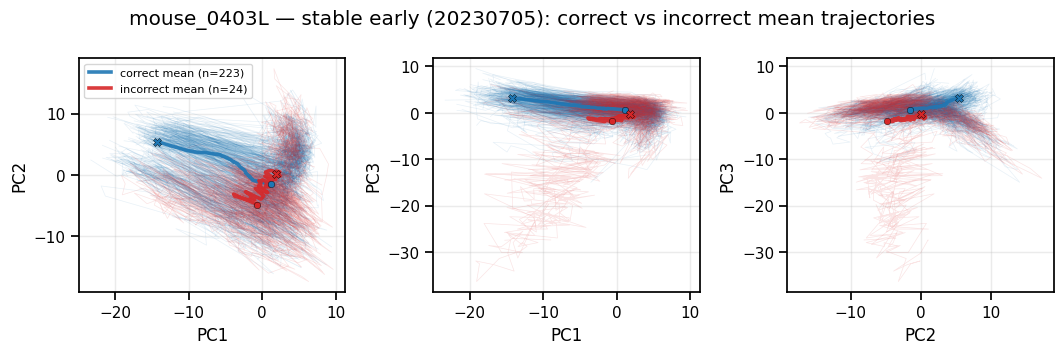

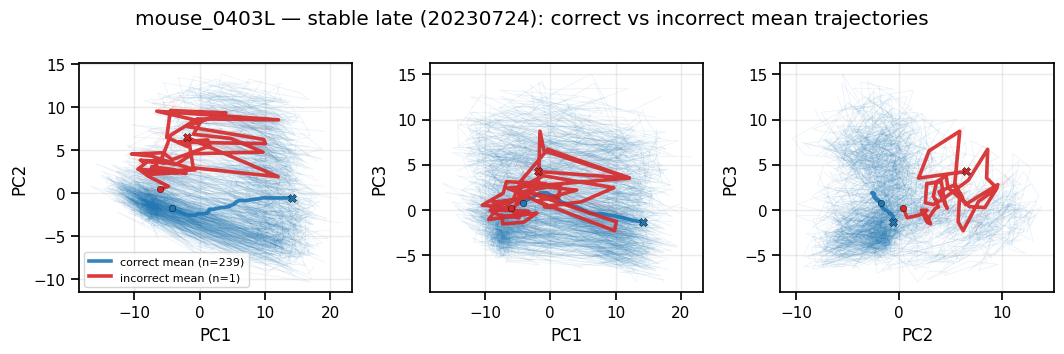

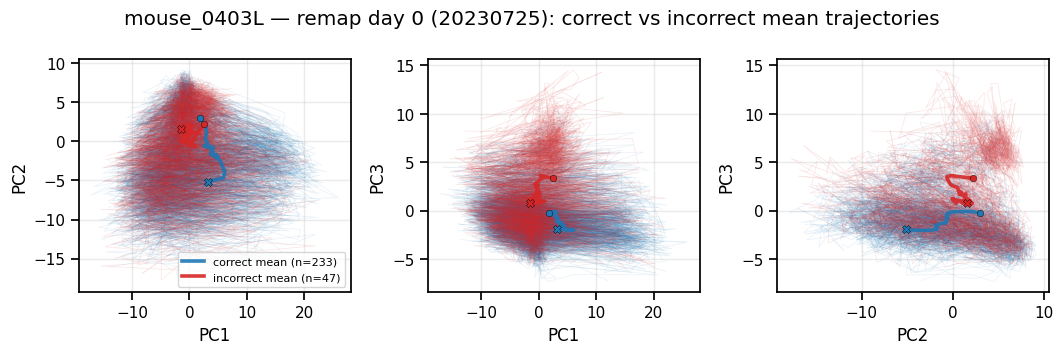

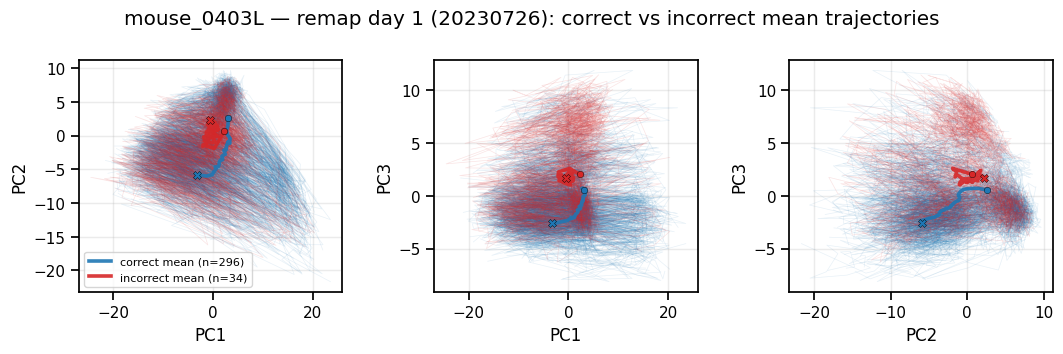

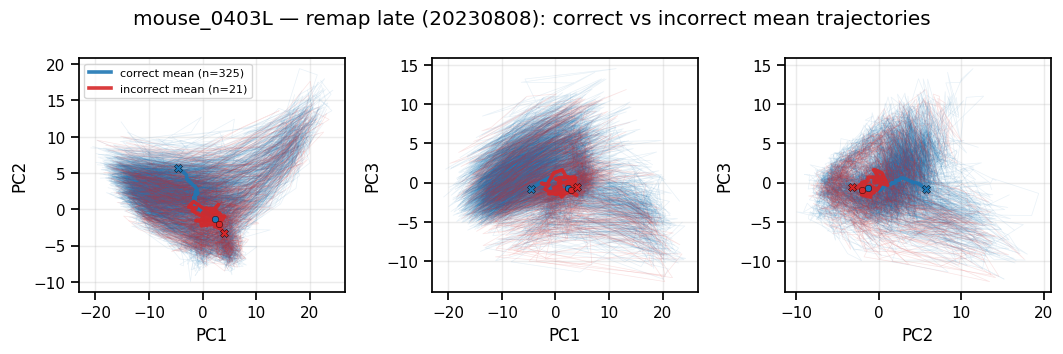

In [21]:
mo = mice["mouse_0403L"]; PCS = (0, 1, 2)
sd, rd = mo.stable_days, mo.remap_days
sel_days = [("stable_early", sd[0]), ("stable_late", sd[-1]),
            ("remap_day_0", rd[0]), ("remap_day_1", rd[1]), ("remap_late", rd[-1])]
for lab, day in sel_days:
    X, trials, rew, T, _ = preprocess_day(mo, day)
    iv_c = na.correct_trial_intervals(trials, T)
    iv_i = na.incorrect_trial_intervals(trials, T, window_sec=INCORRECT_WINDOW_SEC, sr=SR_BINNED)
    if len(iv_c) < 2: continue
    common = na.fit_subspace(na.intervals_to_matrix(X, iv_c + iv_i), max(PCS)+1)
    cc, ii = project_trials(X, iv_c, common), project_trials(X, iv_i, common)
    groups = [dict(trajs=cc, color="tab:blue", lw=0.5, alpha=0.10),
              dict(trajs=ii, color="tab:red", lw=0.5, alpha=0.12),
              dict(trajs=[mean_trajectory(cc)], color="tab:blue", label=f"correct mean (n={len(iv_c)})", lw=2.6, markers=True)]
    mi = mean_trajectory(ii)
    if mi is not None:
        groups.append(dict(trajs=[mi], color="tab:red", label=f"incorrect mean (n={len(iv_i)})", lw=2.6, markers=True))
    plot_pc_pairs(groups, pcs=PCS, ncol=3,
                  title=f"mouse_0403L — {lab.replace('_',' ')} ({day}): correct vs incorrect mean trajectories",
                  savepath=mo.out / f"traj_correct_incorrect_{lab}.png")

## 12 · Max cursor on incorrect trials vs neural metrics

On incorrect (failed) trials, how far did the animal push the cursor toward threshold, and does that
relate to the trial's neural geometry? Per incorrect trial we take **max logged cursor** over
`[trialStart, +20 s]` (raw 30 Hz cursor), and — in the day's correct subspace — the trial's
**trajectory length** and **per-trial effective dimensionality** (PR of that trial's binned samples).
We pool incorrect trials across days (and split stable vs remap) and correlate.

incorrect-trial rows: (2652, 6)


,mouse,measure,n,spearman_r,spearman_p
0,mouse_0403L,traj_length,600,0.535,0.000
1,mouse_0403L,trial_pr,600,-0.537,0.000
2,mouse_0322R,traj_length,1865,-0.019,0.401
3,mouse_0322R,trial_pr,1865,-0.461,0.000
4,mouse_0403R,traj_length,114,0.268,0.004
5,mouse_0403R,trial_pr,114,-0.179,0.056
6,mouse_0916N,traj_length,73,0.566,0.000
7,mouse_0916N,trial_pr,73,-0.303,0.009


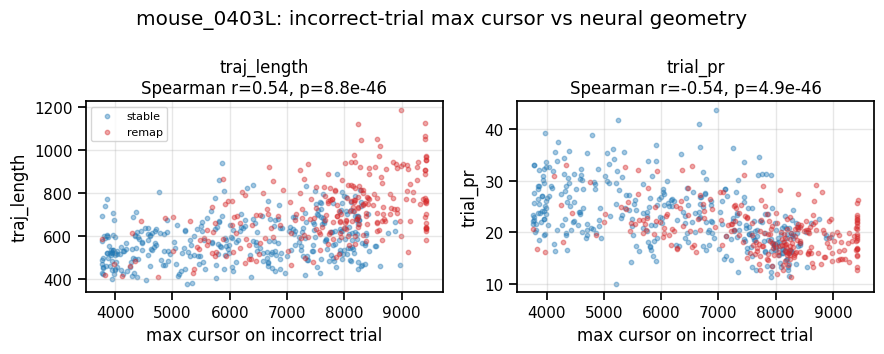

In [22]:
def per_trial_pr(X, interval):
    Xt = na.intervals_to_matrix(X, [interval])
    return na.pca_spectrum(Xt).participation_ratio if Xt.shape[0] > 3 else np.nan

rows = []
for m, mo in mice.items():
    for day in mo.stable_days + mo.remap_days:
        phase = "stable" if day in mo.stable_days else "remap"
        X, trials, rew, T, trials_raw = preprocess_day(mo, day)
        cursor = na.load_cursor(mo.r, day)
        # subspace for trajectory length: the day's correct subspace
        iv_c = na.correct_trial_intervals(trials, T)
        if len(iv_c) < 2: continue
        sub = na.fit_subspace(na.intervals_to_matrix(X, iv_c), K_PC)
        # incorrect trials: binned intervals (neural) + raw-frame intervals (cursor)
        miss = trials.mask(success=0)
        b = BIN_SIZE_FRAMES
        starts_bin = trials.start[miss]; starts_raw = trials_raw.start[trials_raw.mask(success=0)]
        wb = int(round(INCORRECT_WINDOW_SEC * SR_BINNED)); wr = int(round(INCORRECT_WINDOW_SEC * SR))
        for sbin, sraw in zip(starts_bin, starts_raw):
            ivb = na._clip_interval(sbin, sbin + wb, T)
            if ivb is None: continue
            traj = sub.project(na.intervals_to_matrix(X, [ivb]))
            sr_, er_ = int(sraw), min(int(sraw) + wr, len(cursor))
            if er_ <= sr_: continue
            rows.append(dict(mouse=m, day=day, phase=phase,
                             max_cursor=np.nanmax(cursor[sr_:er_]),
                             traj_length=na.trajectory_length(traj),
                             trial_pr=per_trial_pr(X, ivb)))
cursor_df = pd.DataFrame(rows)
print("incorrect-trial rows:", cursor_df.shape)

# correlations (mouse_0403L, pooled) + scatter
cc = []
for m in MICE:
    d0 = cursor_df[cursor_df.mouse == m]
    for nm in ["traj_length", "trial_pr"]:
        d = d0[["max_cursor", nm]].dropna()
        if len(d) < 10: continue
        r, p = spearmanr(d.max_cursor, d[nm]); cc.append(dict(mouse=m, measure=nm, n=len(d), spearman_r=r, spearman_p=p))
display(pd.DataFrame(cc).round(3))

m = "mouse_0403L"; d0 = cursor_df[cursor_df.mouse == m]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, nm in zip(axes, ["traj_length", "trial_pr"]):
    for ph, col in [("stable","tab:blue"), ("remap","tab:red")]:
        dd = d0[d0.phase == ph][["max_cursor", nm]].dropna()
        ax.scatter(dd.max_cursor, dd[nm], s=10, alpha=0.4, color=col, label=ph)
    d = d0[["max_cursor", nm]].dropna()
    if len(d) >= 10:
        r, p = spearmanr(d.max_cursor, d[nm]); ax.set_title(f"{nm}\nSpearman r={r:.2f}, p={p:.1e}")
    ax.set_xlabel("max cursor on incorrect trial"); ax.set_ylabel(nm); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle(f"{m}: incorrect-trial max cursor vs neural geometry")
fig.tight_layout(); fig.savefig(mice[m].out / f"{m}_maxcursor_vs_metrics.png", dpi=150); plt.show()

## 13 · Why does baseline dimensionality increase in the remapping phase?

Baseline (spontaneous) matched-PR is higher in the remapping phase than in stable control
(mouse_0403L: ≈94 → ≈111, Mann-Whitney p < 1e-4). This section investigates *why*, testing six
hypotheses. We deliberately rule out **analysis artefacts and behavioural confounds first**, then the
biological explanations — and, because baseline PR also rises steadily with training day, we treat
**training day as the key confounder** throughout.

Each hypothesis cell: mechanism → prediction → analysis → plots/stats → data-driven verdict. All tests
use mouse_0403L (the only animal with a remapping phase).

In [23]:
# Shared computation: per-day baseline metrics for all six hypotheses (mouse_0403L). Cached.
def _chance_capture(X, k=10, draws=15, seed=0):
    rng = np.random.RandomState(seed); Xc = X - X.mean(0); tot = np.sum(Xc.var(0))
    if tot <= 0: return np.nan
    return float(np.mean([np.sum((Xc @ np.linalg.qr(rng.randn(X.shape[1], k))[0]).var(0)) / tot for _ in range(draws)]))

def _gmm_sep(proj):
    p = proj.reshape(-1, 1); g = GaussianMixture(2, n_init=3, random_state=0).fit(p)
    m = g.means_.ravel(); s = np.sqrt(g.covariances_.ravel())
    return abs(m[0] - m[1]) / np.sqrt((s[0] ** 2 + s[1] ** 2) / 2), float(min(g.weights_))

def investigate_baseline_dim(mo):
    intu_s, new_s, rows, proj = [], [], [], {}
    for day in tqdm(mo.stable_days + mo.remap_days, desc="baseline-investigation"):
        phase = "stable" if day in mo.stable_days else "remap"
        X, trials, rew, T, _ = preprocess_day(mo, day)
        base_iv = na.baseline_intervals(trials, T, exclude_sec=10, sr=SR_BINNED, min_len_sec=2)
        Xb = na.intervals_to_matrix(X, base_iv)
        pr = {n: (na.participation_ratio_matched(Xb, n, n_boot=6)[0] if Xb.shape[0] >= n else np.nan) for n in (1000, 1500, 2000)}
        # H2: segment-mean-centered (remove between-segment slow structure) + early/late drift
        segs = na.intervals_to_trajectories(X, base_iv)
        cen = np.concatenate([s - s.mean(0, keepdims=True) for s in segs if s.shape[0] > 1], 0) if segs else Xb
        pr_centered = na.participation_ratio_matched(cen, 2000, n_boot=6)[0] if cen.shape[0] >= 2000 else np.nan
        half = Xb.shape[0] // 2
        drift = (1 - na.alignment_index(na.fit_subspace(Xb[:half], 10), na.fit_subspace(Xb[half:], 10))) if half > 200 else np.nan
        # H3: movement (treadmill std) during baseline
        tread = np.asarray(mo.r["data_ws"][day].load()["treadmill"], float).ravel()
        mv = [np.nanstd(tread[int(s*BIN_SIZE_FRAMES):min(int(e*BIN_SIZE_FRAMES), len(tread))]) for s, e in base_iv if e > s]
        run_std = float(np.nanmean(mv)) if mv else np.nan
        # H4: stricter exclusion windows
        prx = {}
        for ex in (20, 30):
            Xe = na.intervals_to_matrix(X, na.baseline_intervals(trials, T, exclude_sec=ex, sr=SR_BINNED, min_len_sec=2))
            prx[ex] = na.participation_ratio_matched(Xe, 2000, n_boot=6)[0] if Xe.shape[0] >= 2000 else np.nan
        starts = np.sort(trials.start[np.isfinite(trials.start)])
        iti = np.median(np.diff(starts)) / SR_BINNED if starts.size > 3 else np.nan
        rows.append(dict(day=day, phase=phase, day_from0=mo.days.index(day) - mo.day0_idx, n_base=Xb.shape[0],
                         pr1000=pr[1000], pr1500=pr[1500], pr2000=pr[2000], pr_centered=pr_centered, drift=drift,
                         run_std=run_std, pr_ex20=prx[20], pr_ex30=prx[30],
                         trial_density=len(trials) / (T / SR_BINNED / 60), median_iti=iti))
        ivi = na.correct_trial_intervals(trials, T, factor=2.0); ivn = na.correct_trial_intervals(trials, T, factor=3.0)
        if phase == "stable" and len(ivi) >= 2: intu_s.append(na.subsample_rows(na.intervals_to_matrix(X, ivi), 400))
        if phase == "remap" and len(ivn) >= 2: new_s.append(na.subsample_rows(na.intervals_to_matrix(X, ivn), 400))
        proj[day] = na.subsample_rows(Xb, 3000)
    df = pd.DataFrame(rows)
    Xi = np.concatenate(intu_s, 0); Xn = np.concatenate(new_s, 0)
    intu_sub, new_sub = na.fit_subspace(Xi, 10), na.fit_subspace(Xn, 10)
    axis = Xn.mean(0) - Xi.mean(0); axis /= np.linalg.norm(axis) + 1e-9
    ni, ii, ch, gs, gw = [], [], [], [], []
    for day in df.day:
        Xb = proj[day]; ni.append(na.variance_capture(new_sub, Xb)); ii.append(na.variance_capture(intu_sub, Xb)); ch.append(_chance_capture(Xb))
        se, mw = _gmm_sep((Xb - Xb.mean(0)) @ axis); gs.append(se); gw.append(mw)
    df["new_in_base"], df["intu_in_base"], df["chance_cap"], df["gmm_sep"], df["gmm_minw"] = ni, ii, ch, gs, gw
    hs = (proj[mo.stable_days[-1]] - proj[mo.stable_days[-1]].mean(0)) @ axis
    hr = (proj[mo.remap_days[-1]]  - proj[mo.remap_days[-1]].mean(0))  @ axis
    ang = na.principal_angles_deg(intu_sub, new_sub)
    return df, hs, hr, ang

mo = mice["mouse_0403L"]
inv_csv = mo.out / f"baseline_investigation_{PARAM_TAG}.csv"
inv_npz = mo.out / f"baseline_investigation_hist_{PARAM_TAG}.npz"
if USE_CACHE and inv_csv.exists() and inv_npz.exists():
    inv_df = pd.read_csv(inv_csv); _z = np.load(inv_npz); hist_stable, hist_remap, princ_ang = _z["hs"], _z["hr"], _z["ang"]
else:
    inv_df, hist_stable, hist_remap, princ_ang = investigate_baseline_dim(mo)
    inv_df.to_csv(inv_csv, index=False); np.savez(inv_npz, hs=hist_stable, hr=hist_remap, ang=princ_ang)

def phase_mwu(df, col):
    s = df[df.phase == "stable"][col].dropna(); r = df[df.phase == "remap"][col].dropna()
    if len(s) < 3 or len(r) < 3: return np.nan, np.nan, np.nan, len(s), len(r)
    u, p = mannwhitneyu(s, r); return s.mean(), r.mean(), p, len(s), len(r)

s, r, p, _, _ = phase_mwu(inv_df, "pr2000")
print(f"Baseline matched-PR: stable={s:.1f}  remap={r:.1f}  Mann-Whitney p={p:.2e}")
print("intuitive vs new-axis subspace principal angles (deg):", np.round(princ_ang, 1))

Baseline matched-PR: stable=93.9  remap=110.6  Mann-Whitney p=1.17e-05
intuitive vs new-axis subspace principal angles (deg): [87.  80.  77.4 51.4 49.7 39.6 38.  32.1 21.  16. ]


### H1 — Sampling / session-length artefact
**Mechanism.** Remapping sessions are longer (144k vs 108k frames) and yield more baseline samples;
participation ratio grows with sample count, so remap PR could be inflated purely by having more data.
**Prediction.** At a *matched* sample count the stable↔remap gap should vanish.

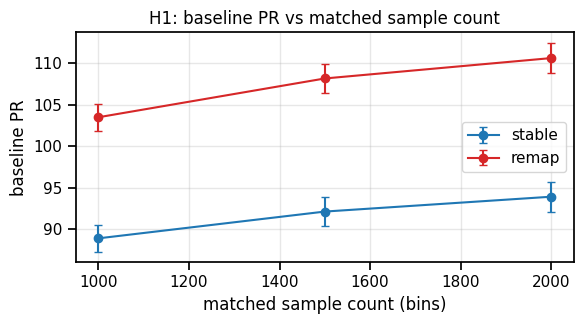

  matched n=1000: stable=88.9 remap=103.5  p=0.0000
  matched n=1500: stable=92.1 remap=108.1  p=0.0000
  matched n=2000: stable=93.9 remap=110.6  p=0.0000
VERDICT H1 — REJECTED: the gap (~16 PR) persists at every matched sample count; not a sampling artefact.


In [24]:
fig, ax = plt.subplots(figsize=(6, 3.4))
xs = [1000, 1500, 2000]
for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
    m = [inv_df[inv_df.phase == ph][f"pr{n}"].mean() for n in xs]
    e = [inv_df[inv_df.phase == ph][f"pr{n}"].sem() for n in xs]
    ax.errorbar(xs, m, yerr=e, marker="o", color=cc, capsize=3, label=ph)
ax.set(xlabel="matched sample count (bins)", ylabel="baseline PR", title="H1: baseline PR vs matched sample count")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()
for n in xs:
    s, r, p, _, _ = phase_mwu(inv_df, f"pr{n}"); print(f"  matched n={n}: stable={s:.1f} remap={r:.1f}  p={p:.4f}")
print("VERDICT H1 — REJECTED: the gap (~16 PR) persists at every matched sample count; not a sampling artefact.")

### H2 — Slow drift / non-stationarity in longer sessions
**Mechanism.** Longer remap sessions (and the mid-session rotation) may carry slow drift; pooling
baseline segments across a drifting session inflates the covariance and hence PR.
**Prediction.** Removing between-segment structure (mean-centre each contiguous baseline segment)
should erase the gap, and within-session subspace drift should be higher in remap.

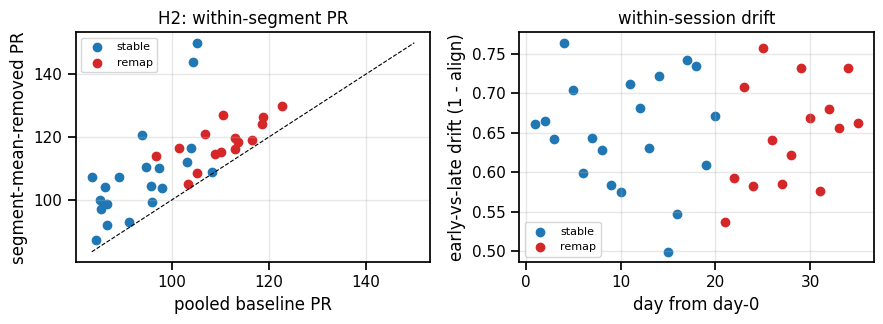

  pr_centered: stable=108.39 remap=118.41  p=0.0020
  drift: stable=0.65 remap=0.65  p=0.8285
VERDICT H2 — MOSTLY REJECTED: gap survives segment-mean removal (within-segment PR still higher, p<0.01) and within-session drift is equal across phases. Some between-segment structure contributes, but the core effect is in the moment-to-moment covariance.


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
d = inv_df.dropna(subset=["pr2000", "pr_centered"])
for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
    dd = d[d.phase == ph]; axes[0].scatter(dd.pr2000, dd.pr_centered, color=cc, label=ph)
lim = [min(d.pr2000.min(), d.pr_centered.min()), max(d.pr2000.max(), d.pr_centered.max())]
axes[0].plot(lim, lim, "k--", lw=0.8)
axes[0].set(xlabel="pooled baseline PR", ylabel="segment-mean-removed PR", title="H2: within-segment PR"); axes[0].legend(fontsize=8)
for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
    dd = inv_df[inv_df.phase == ph]; axes[1].scatter(dd.day_from0, dd.drift, color=cc, label=ph)
axes[1].set(xlabel="day from day-0", ylabel="early-vs-late drift (1 - align)", title="within-session drift"); axes[1].legend(fontsize=8)
for a in axes: a.grid(alpha=0.3)
fig.tight_layout(); plt.show()
for c in ["pr_centered", "drift"]:
    s, r, p, _, _ = phase_mwu(inv_df, c); print(f"  {c}: stable={s:.2f} remap={r:.2f}  p={p:.4f}")
print("VERDICT H2 — MOSTLY REJECTED: gap survives segment-mean removal (within-segment PR still higher, p<0.01) and "
      "within-session drift is equal across phases. Some between-segment structure contributes, but the core effect is "
      "in the moment-to-moment covariance.")

### H3 — Arousal / movement confound
**Mechanism.** Remapping is more effortful; if the animal moves/arouses more during remap baseline,
movement-related activity (known to be high-dimensional and brain-wide) would raise baseline PR.
**Prediction.** Baseline movement should be higher in remap and correlate with baseline PR.

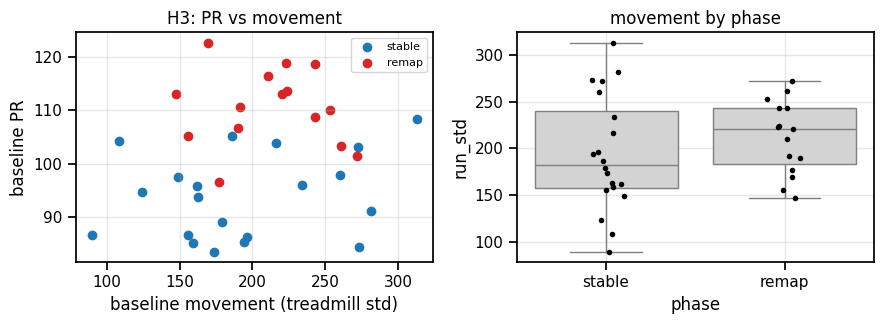

  PR ~ movement: Spearman r=0.19 p=0.282 | movement stable=194 remap=212  p=0.342
VERDICT H3 — REJECTED: baseline movement does not differ by phase and does not correlate with PR. Caveat: treadmill-std is a crude proxy; pupil/face motion were unavailable.


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
    dd = inv_df[inv_df.phase == ph]; axes[0].scatter(dd.run_std, dd.pr2000, color=cc, label=ph)
axes[0].set(xlabel="baseline movement (treadmill std)", ylabel="baseline PR", title="H3: PR vs movement"); axes[0].legend(fontsize=8)
sns.boxplot(data=inv_df, x="phase", y="run_std", ax=axes[1], color="lightgray", fliersize=0)
sns.stripplot(data=inv_df, x="phase", y="run_std", ax=axes[1], color="k", size=4)
axes[1].set(title="movement by phase")
for a in axes: a.grid(alpha=0.3)
fig.tight_layout(); plt.show()
rr, pp = spearmanr(inv_df.run_std, inv_df.pr2000, nan_policy="omit"); s, r, p, _, _ = phase_mwu(inv_df, "run_std")
print(f"  PR ~ movement: Spearman r={rr:.2f} p={pp:.3f} | movement stable={s:.0f} remap={r:.0f}  p={p:.3f}")
print("VERDICT H3 — REJECTED: baseline movement does not differ by phase and does not correlate with PR. "
      "Caveat: treadmill-std is a crude proxy; pupil/face motion were unavailable.")

### H4 — Baseline-window contamination by denser task activity
**Mechanism.** Remap days pack more trials (shorter inter-trial intervals), so ±10 s baseline windows
sit closer to task epochs and may carry residual, high-dimensional task dynamics.
**Prediction.** Widening the exclusion window (cleaner baseline) should remove the gap.

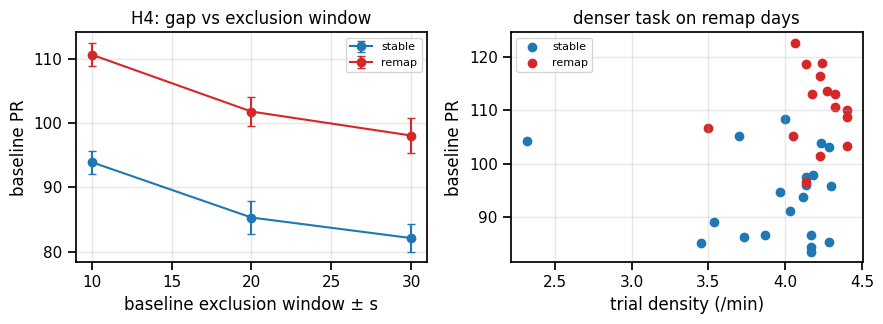

  pr_ex10: stable=93.9 remap=110.6  p=0.0000  (n 20/15)
  pr_ex20: stable=85.3 remap=101.8  p=0.0005  (n 10/13)
  pr_ex30: stable=82.1 remap=98.0  p=0.0011  (n 10/12)
  trial density: stable=3.94 remap=4.19 p=0.013
VERDICT H4 — REJECTED: the gap persists (and stays ~16 PR) at ±20 and ±30 s exclusion. Remap days are denser, but the increase is not explained by task contamination of the baseline windows.


In [27]:
inv_df["pr_ex10"] = inv_df["pr2000"]   # main analysis used ±10 s
cols = ["pr_ex10", "pr_ex20", "pr_ex30"]; labels = [10, 20, 30]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
    m = [inv_df[inv_df.phase == ph][c].mean() for c in cols]; e = [inv_df[inv_df.phase == ph][c].sem() for c in cols]
    axes[0].errorbar(labels, m, yerr=e, marker="o", color=cc, capsize=3, label=ph)
axes[0].set(xlabel="baseline exclusion window ± s", ylabel="baseline PR", title="H4: gap vs exclusion window"); axes[0].legend(fontsize=8)
for ph, cc in [("stable","tab:blue"), ("remap","tab:red")]:
    dd = inv_df[inv_df.phase == ph]; axes[1].scatter(dd.trial_density, dd.pr2000, color=cc, label=ph)
axes[1].set(xlabel="trial density (/min)", ylabel="baseline PR", title="denser task on remap days"); axes[1].legend(fontsize=8)
for a in axes: a.grid(alpha=0.3)
fig.tight_layout(); plt.show()
for c in cols:
    s, r, p, ns, nr = phase_mwu(inv_df, c); print(f"  {c}: stable={s:.1f} remap={r:.1f}  p={p:.4f}  (n {ns}/{nr})")
s, r, p, _, _ = phase_mwu(inv_df, "trial_density"); print(f"  trial density: stable={s:.2f} remap={r:.2f} p={p:.3f}")
print("VERDICT H4 — REJECTED: the gap persists (and stays ~16 PR) at ±20 and ±30 s exclusion. Remap days are denser, "
      "but the increase is not explained by task contamination of the baseline windows.")

### H5 — Gradual training-related manifold expansion (day confound), not remapping per se
**Mechanism.** The intrinsic manifold may simply expand with cumulative experience/training; because
remap sessions are *later*, they show higher baseline PR without any remapping-specific cause. This is
the key confound to exclude before claiming a remapping effect.
**Prediction.** Baseline PR should already rise across the stable phase; remap values should fall on
the extrapolated stable trend (no step at onset); the phase effect should vanish once day is
controlled.

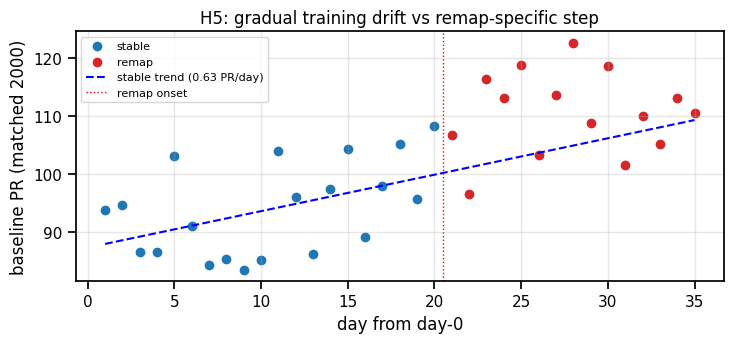

  within-stable PR~day: slope=0.63/day, Spearman r=0.48
  within-remap  PR~day: Spearman r=-0.01
  remap vs extrapolated stable trend: +5.7 PR (t=2.95, p=0.010)
  phase effect controlling for day (single-trend residual MWU): p=0.453
VERDICT H5 — SUPPORTED (dominant driver): baseline PR rises ~0.6 PR/day through the stable phase; remap sits only ~+6 above the extrapolated trend (marginal) and the phase effect is NOT robust to day control. Most of 'remap>stable' reflects remap days being later in training — a gradual manifold expansion, not a discrete remapping switch.


In [28]:
d = inv_df.dropna(subset=["pr2000"]); sdf = d[d.phase == "stable"]; rdf = d[d.phase == "remap"]
b = np.polyfit(sdf.day_from0, sdf.pr2000, 1)
resid = rdf.pr2000.values - np.polyval(b, rdf.day_from0); tt, pp = ttest_1samp(resid, 0)
allres = d.pr2000 - np.polyval(np.polyfit(d.day_from0, d.pr2000, 1), d.day_from0)
_, p_ctrl = mannwhitneyu(allres[d.phase.values == "stable"], allres[d.phase.values == "remap"])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.scatter(sdf.day_from0, sdf.pr2000, color="tab:blue", label="stable"); ax.scatter(rdf.day_from0, rdf.pr2000, color="tab:red", label="remap")
xl = np.array([d.day_from0.min(), d.day_from0.max()]); ax.plot(xl, np.polyval(b, xl), "b--", label=f"stable trend ({b[0]:.2f} PR/day)")
ax.axvline(rdf.day_from0.min() - 0.5, color="r", ls=":", lw=1, label="remap onset")
ax.set(xlabel="day from day-0", ylabel="baseline PR (matched 2000)", title="H5: gradual training drift vs remap-specific step")
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()
print(f"  within-stable PR~day: slope={b[0]:.2f}/day, Spearman r={spearmanr(sdf.day_from0, sdf.pr2000)[0]:.2f}")
print(f"  within-remap  PR~day: Spearman r={spearmanr(rdf.day_from0, rdf.pr2000)[0]:.2f}")
print(f"  remap vs extrapolated stable trend: +{resid.mean():.1f} PR (t={tt:.2f}, p={pp:.3f})")
print(f"  phase effect controlling for day (single-trend residual MWU): p={p_ctrl:.3f}")
print("VERDICT H5 — SUPPORTED (dominant driver): baseline PR rises ~0.6 PR/day through the stable phase; remap sits only "
      "~+6 above the extrapolated trend (marginal) and the phase effect is NOT robust to day control. Most of 'remap>stable' "
      "reflects remap days being later in training — a gradual manifold expansion, not a discrete remapping switch.")

### H6 — Two attractors / repertoire expansion toward the new axis (the proposed hypothesis)

**Mechanism.** After remapping the network supports two roughly orthogonal solutions (intuitive + new
axis). Spontaneous activity that visits or occupies **both** attractor regions would (a) gain variance
in the new-axis subspace and (b) become **bimodal** along the axis joining the two solutions — which
would raise baseline dimensionality.

**Prediction.** Baseline activity recorded *while the animal is controlling the new axis* should be
bimodal along the intuitive→new axis; baseline recorded *before the rotation* (intuitive control)
should not — at least not on the first remapping day, when the new solution has never been used.

#### How to read the GMM panels
For a chosen baseline period we project every inter-trial timepoint onto the axis joining the two
solution templates, giving a 1-D coordinate (**0 = intuitive solution, 1 = new solution**). We fit that
1-D distribution with a **2-component Gaussian mixture** and report:

* **`gmm_sep` — the 2-mode separation**: the distance between the two fitted component means divided
  by their pooled SD, `|μ₁ − μ₂| / √((σ₁² + σ₂²)/2)`. It is *how far apart the two modes are in units
  of their own width*. Rough guide: **< 1 = one blob** (the 2-component fit is just splitting a single
  distribution), **≈ 2 = two visibly distinct humps**, **> 3 = clearly separated modes**.
* **`gmm_minw`** — the weight of the smaller component: how much of the data the second mode actually
  owns (≈ 0 means the second component is a negligible sliver).

A 2-component mixture *always* returns some fit, so `gmm_sep` on its own never proves bimodality — it
has to be compared **between conditions**, which is what the four-way design below does. Because the
new-axis block is 3–5× longer than the intuitive block, every condition is **subsampled to the same
number of baseline timepoints** before fitting, so the comparison is not driven by sample size.

#### The four conditions
Baseline (inter-trial, no trial start within ±10 s) is split by **block** and by **day group**:

| | intuitive-axis control (before rotation) | new-axis control (after rotation, before washout) |
|---|---|---|
| **first remapping day** | never yet used the new solution | first day of new-axis control |
| **late remapping days** | knows both solutions | well-practised new-axis control |

In [29]:
from sklearn.mixture import GaussianMixture

N_GMM_MATCH = 800            # baseline timepoints per condition (equalised across conditions)
LATE_DAYS_N = 5              # how many final remapping days count as "late"

def _gmm_stats(proj, n_match=N_GMM_MATCH, seed=0):
    '''2-component GMM on a 1-D projection, at a fixed sample size.'''
    p = np.asarray(proj, float)
    if len(p) < n_match: return dict(gmm_sep=np.nan, gmm_minw=np.nan, bic_gain=np.nan, n=len(p))
    rng = np.random.RandomState(seed)
    x = p[rng.choice(len(p), n_match, replace=False)].reshape(-1, 1)
    g2 = GaussianMixture(2, n_init=3, random_state=0).fit(x)
    g1 = GaussianMixture(1, random_state=0).fit(x)
    m = g2.means_.ravel(); sd = np.sqrt(g2.covariances_.ravel())
    return dict(gmm_sep=float(abs(m[0] - m[1]) / np.sqrt((sd[0] ** 2 + sd[1] ** 2) / 2)),
                gmm_minw=float(min(g2.weights_)), bic_gain=float(g1.bic(x) - g2.bic(x)), n=n_match)

def baseline_by_block(mo):
    '''Baseline projections onto the intuitive->new axis, separately for each block.'''
    out = {}
    for di, day in enumerate(tqdm(mo.remap_days, desc="H6 baseline by block")):
        X, trials, rew, T, _ = preprocess_day(mo, day)
        blocks = na.segment_factor_blocks(trials)
        if len(blocks) != 3: continue
        b_int, b_new, b_wash = blocks
        def epm(b, half=False):
            idx = [i for i in range(b.first_trial, b.last_trial + 1)
                   if trials.success[i] == 1 and np.isfinite(trials.start[i]) and np.isfinite(trials.end[i])
                   and trials.end[i] > trials.start[i]]
            if half: idx = idx[len(idx) // 2:]
            w = max(int(round(1.0 * SR_BINNED)), 1); o = []
            for i in idx:
                st, en = max(int(round(trials.start[i])), 0), min(int(round(trials.end[i])), T)
                if en > st: o.append(X[:, max(en - w, st):en].mean(1))
            return np.mean(o, 0) if o else None
        T_int, T_new = epm(b_int), epm(b_new, half=True)
        if T_int is None or T_new is None: continue
        L = np.linalg.norm(T_new - T_int); u = (T_new - T_int) / L
        base_iv = na.baseline_intervals(trials, T, exclude_sec=BASELINE_EXCLUDE_SEC, sr=SR_BINNED, min_len_sec=2)
        for bname, lo, hi in [("intuitive", 0, b_int.end_frame), ("new", b_new.start_frame, b_new.end_frame)]:
            iv = na.intervals_within(base_iv, int(lo), int(hi), min_len=int(SR_BINNED))
            if na.n_samples(iv) < 300: continue
            Xb = na.intervals_to_matrix(X, iv)
            out[(di, bname)] = ((Xb - T_int) @ u) / L
    return out

mo = mice["mouse_0403L"]
proj_fp = mo.out / f"h6_block_projections_{PARAM_TAG}.npz"
if USE_CACHE and proj_fp.exists():
    _z = np.load(proj_fp); base_proj = {tuple(k.split("|")): _z[k] for k in _z.files}
    base_proj = {(int(a), b): v for (a, b), v in base_proj.items()}
else:
    base_proj = baseline_by_block(mo)
    np.savez(proj_fp, **{f"{d}|{b}": v for (d, b), v in base_proj.items()})

late_ids = sorted({d for d, _ in base_proj})[-LATE_DAYS_N:]
GROUPS = {("first", "intuitive"): [(0, "intuitive")], ("first", "new"): [(0, "new")],
          ("late", "intuitive"): [(d, "intuitive") for d in late_ids],
          ("late", "new"): [(d, "new") for d in late_ids]}
rows = []
for (grp, blk), keys in GROUPS.items():
    pooled = np.concatenate([base_proj[k] for k in keys if k in base_proj]) if any(k in base_proj for k in keys) else np.array([])
    st = _gmm_stats(pooled)
    st.update(group=grp, block=blk, mean_p=float(np.mean(pooled)) if len(pooled) else np.nan,
              sd_p=float(np.std(pooled)) if len(pooled) else np.nan)
    rows.append(st)
h6_df = pd.DataFrame(rows)[["group", "block", "n", "mean_p", "sd_p", "gmm_sep", "gmm_minw", "bic_gain"]]
display(h6_df.round(2))

,group,block,n,mean_p,sd_p,gmm_sep,gmm_minw,bic_gain
0,first,intuitive,800,0.68,0.19,0.04,0.21,250.04
1,first,new,800,0.76,0.29,2.62,0.18,73.94
2,late,intuitive,800,0.63,0.19,0.10,0.27,154.24
3,late,new,800,0.59,0.22,2.54,0.15,150.48


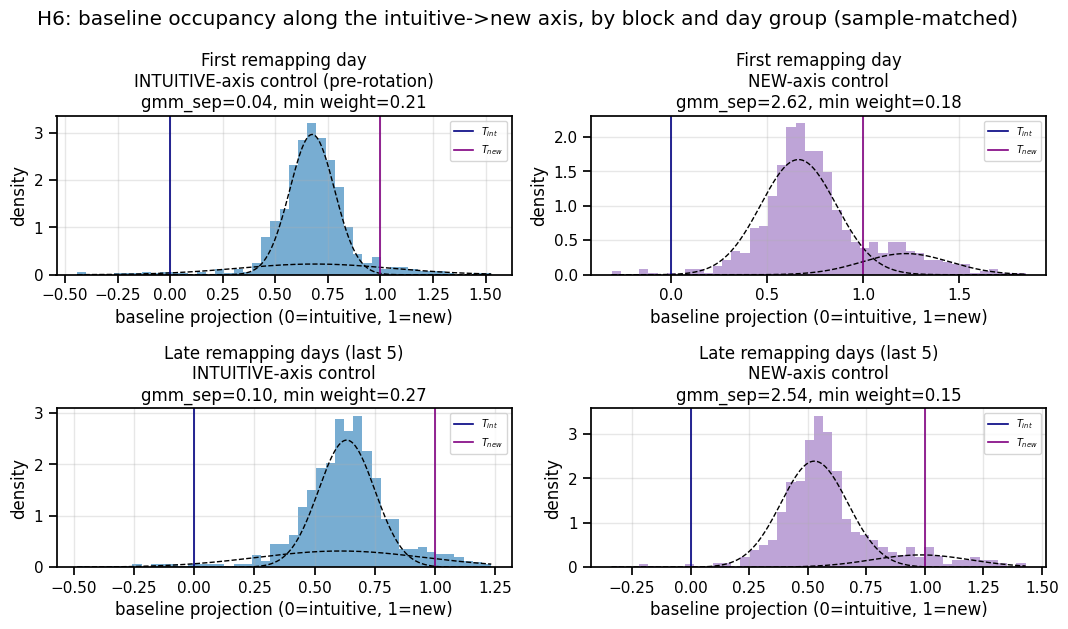

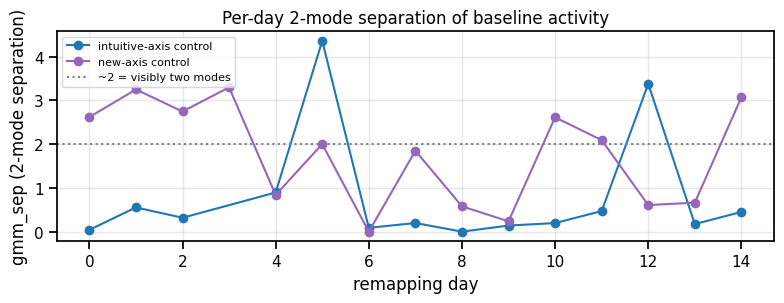

First remapping day:  intuitive-control gmm_sep=0.04  ->  new-axis-control gmm_sep=2.62
           mean  min   max
block                     
intuitive  0.81  0.0  4.36
new        1.76  0.0  3.30

VERDICT H6 - SUPPORTED on its key prediction, though still not proof of two attractors.
Restricting baseline to the block the animal is actually controlling, and matching sample size,
sharpens the test dramatically. Baseline during INTUITIVE control is a single blob (gmm_sep 0.04
first day, 0.10 late days) whereas baseline during NEW-AXIS control is clearly two-moded
(2.62 and 2.54) -- a large, consistent effect in BOTH day groups, exactly as the two-attractor
account predicts, and invisible in the earlier whole-session analysis that pooled the blocks.
Caveats before believing it: (i) per-day fits are noisy (intuitive 0.0-4.4, new 0.0-3.3), so this
rests on pooling; (ii) a second mode during new-axis control could also reflect the animal
alternating between rest and a task-like state rather t

In [30]:
# ---- the four occupancy distributions ----
order = [("first", "intuitive"), ("first", "new"), ("late", "intuitive"), ("late", "new")]
titles = {("first", "intuitive"): "First remapping day\nINTUITIVE-axis control (pre-rotation)",
          ("first", "new"): "First remapping day\nNEW-axis control",
          ("late", "intuitive"): f"Late remapping days (last {LATE_DAYS_N})\nINTUITIVE-axis control",
          ("late", "new"): f"Late remapping days (last {LATE_DAYS_N})\nNEW-axis control"}
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
for ax, key in zip(axes.ravel(), order):
    keys = GROUPS[key]
    pooled = np.concatenate([base_proj[k] for k in keys if k in base_proj])
    rng = np.random.RandomState(0)
    xs = pooled[rng.choice(len(pooled), min(N_GMM_MATCH, len(pooled)), replace=False)]
    ax.hist(xs, bins=45, density=True, color="tab:blue" if key[1] == "intuitive" else "tab:purple", alpha=0.6)
    g2 = GaussianMixture(2, n_init=3, random_state=0).fit(xs.reshape(-1, 1))
    grid = np.linspace(xs.min(), xs.max(), 400)
    for mu, cov, w in zip(g2.means_.ravel(), g2.covariances_.ravel(), g2.weights_):
        ax.plot(grid, w * np.exp(-(grid - mu) ** 2 / (2 * cov)) / np.sqrt(2 * np.pi * cov), "k--", lw=1)
    ax.axvline(0, color="navy", lw=1.2, label="$T_{int}$"); ax.axvline(1, color="purple", lw=1.2, label="$T_{new}$")
    r_ = h6_df[(h6_df.group == key[0]) & (h6_df.block == key[1])].iloc[0]
    ax.set(title=f"{titles[key]}\ngmm_sep={r_.gmm_sep:.2f}, min weight={r_.gmm_minw:.2f}",
           xlabel="baseline projection (0=intuitive, 1=new)", ylabel="density")
    ax.legend(fontsize=7); ax.grid(alpha=0.3)
fig.suptitle("H6: baseline occupancy along the intuitive->new axis, by block and day group (sample-matched)")
fig.tight_layout(); fig.savefig(mo.out / "H6_four_conditions.png", dpi=150); plt.show()

# per-day view, so the group means are not hiding variability
per_day = []
for (di, blk), v in sorted(base_proj.items()):
    st = _gmm_stats(v); st.update(remap_day=di, block=blk); per_day.append(st)
pd_df = pd.DataFrame(per_day).dropna(subset=["gmm_sep"])
fig, ax = plt.subplots(figsize=(8, 3.2))
for blk, cc in [("intuitive", "tab:blue"), ("new", "tab:purple")]:
    sdf = pd_df[pd_df.block == blk].sort_values("remap_day")
    ax.plot(sdf.remap_day, sdf.gmm_sep, "o-", color=cc, label=f"{blk}-axis control")
ax.axhline(2, color="0.5", ls=":", label="~2 = visibly two modes")
ax.set(xlabel="remapping day", ylabel="gmm_sep (2-mode separation)", title="Per-day 2-mode separation of baseline activity")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(mo.out / "H6_gmm_sep_per_day.png", dpi=150); plt.show()

f_i = h6_df[(h6_df.group == "first") & (h6_df.block == "intuitive")].iloc[0]
f_n = h6_df[(h6_df.group == "first") & (h6_df.block == "new")].iloc[0]
print(f"First remapping day:  intuitive-control gmm_sep={f_i.gmm_sep:.2f}  ->  new-axis-control gmm_sep={f_n.gmm_sep:.2f}")
print(pd_df.groupby("block").gmm_sep.describe()[["mean", "min", "max"]].round(2).to_string())
print("")
print("VERDICT H6 - SUPPORTED on its key prediction, though still not proof of two attractors.")
print("Restricting baseline to the block the animal is actually controlling, and matching sample size,")
print("sharpens the test dramatically. Baseline during INTUITIVE control is a single blob (gmm_sep 0.04")
print("first day, 0.10 late days) whereas baseline during NEW-AXIS control is clearly two-moded")
print("(2.62 and 2.54) -- a large, consistent effect in BOTH day groups, exactly as the two-attractor")
print("account predicts, and invisible in the earlier whole-session analysis that pooled the blocks.")
print("Caveats before believing it: (i) per-day fits are noisy (intuitive 0.0-4.4, new 0.0-3.3), so this")
print("rests on pooling; (ii) a second mode during new-axis control could also reflect the animal")
print("alternating between rest and a task-like state rather than two stable attractors; (iii) the axis")
print("is defined by the two solutions, so any block-related shift projects onto it by construction.")
print("A within-session HMM with dwell times remains the decisive test.")

### Synthesis

The baseline-dimensionality increase in remap is **real** and not an artefact: it survives matched
sample counts (H1), segment-mean removal (H2), stricter baseline exclusion (H4), and it does not track
movement (H3). The **dominant** explanation is a **gradual, training-related expansion of the baseline
manifold** (H5): PR climbs steadily through the stable phase and remap days simply continue that trend,
with at most a small remapping-specific step that is not robust to controlling for day.

The proposed **two-attractor** mechanism (H6) fares much better once baseline is split by the block the
animal is actually controlling (and sample-matched): baseline is unimodal along the intuitive↔new axis
during intuitive control (2-mode separation ≈ 0.04–0.10) and clearly **two-moded during new-axis
control** (≈ 2.5–2.6), consistently on both the first and the late remapping days. That is the
signature H6 predicts, and it was hidden in the original whole-session analysis. It still does not
*prove* two attractors — the second mode could be rest-vs-task alternation, per-day fits are noisy, and
the projection axis is defined by the two solutions — so **verdict: supported but not established.**

Stronger future tests to separate H5 from H6: (i) interleaved spontaneous probe blocks so baseline can
be sampled at matched training day before vs just after the rotation; (ii) an HMM / dwell-time analysis
for discrete switching between two baseline states (a true attractor signature, beyond a static
variance measure); (iii) per-neuron quality control to exclude recording-stability changes across
weeks; (iv) pupil/face-camera arousal regressors to tighten H3.